# Etapa 5 — Previsão de Demanda — Produtos AY
## Walk-Forward Validation | Holt-Winters · SARIMA · XGBoost · Prophet

**Objetivo:** Prever a demanda mensal dos 6 produtos de classe AY para os próximos 3 meses, selecionando automaticamente o modelo de menor erro por produto.

| Parâmetro | Valor |
|---|---|
| Produtos analisados | 6 (classe AY — alta prioridade, demanda variável) |
| Janela de validação | Walk-forward — 6 passos temporais |
| Métrica de seleção | MAPE (menor erro percentual absoluto médio) |
| Horizonte de previsão | 3 meses |

---


## Horizonte de Previsão — Justificativa dos 3 Meses

O horizonte de 3 meses foi escolhido por adequação ao perfil AY: produtos com
demanda errática perdem confiabilidade de previsão rapidamente, tornando janelas
mais longas pouco confiáveis no nível de SKU. Como o objetivo é operacional —
alimentar o cálculo de ES e PP —, o curto prazo equilibra acurácia e utilidade
prática, alinhado à recomendação de Silver, Pyke e Thomas (2017) para itens de
alta variabilidade.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import logging
logging.getLogger('prophet').setLevel(logging.WARNING)
logging.getLogger('cmdstanpy').setLevel(logging.WARNING)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
from scipy import stats
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

try:
    from prophet import Prophet
    PROPHET_OK = True
except ImportError:
    PROPHET_OK = False
    print('Prophet nao instalado. Execute: pip install prophet')

plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
})
print('Bibliotecas carregadas!')


Importing plotly failed. Interactive plots will not work.


Bibliotecas carregadas!


### Preparação da modelagem da Previsao

In [2]:
N_TEST    = 6   # meses usados na janela de walk-forward
HORIZONTE = 3   # meses a prever

# Carregamento
df_raw  = pd.read_csv('data/base_tratada.csv')
df_raw['data_pedido'] = pd.to_datetime(df_raw['data_pedido'])

abc_xyz = pd.read_csv('data/classificacao_abc_xyz.csv')
df_ay   = abc_xyz[abc_xyz['classe_abcxyz'] == 'AY'].copy()
IDS_AY  = df_ay['id_produto'].tolist()
NOMES   = dict(zip(df_ay['id_produto'], df_ay['produto']))


Com base nos 36 meses de histórico disponível (janeiro/2022 a dezembro/2024), a janela de validação foi definida em 6 passos temporais como equilíbrio entre representatividade do teste e suficiência dos dados de treino. Os modelos estatísticos sazonais utilizados — Holt-Winters e SARIMA com periodicidade 12 — exigem no mínimo dois ciclos sazonais completos (24 meses) para estimar seus parâmetros com confiabilidade; com N_TEST = 6, o menor conjunto de treino utilizado contém 30 meses, mantendo margem segura acima desse limite. Além disso, seis meses de teste cobrem diferentes fases do ciclo sazonal anual — incluindo tanto períodos de pico quanto de baixa demanda — tornando o MAPE resultante mais representativo do erro real do modelo ao longo do ano, ao contrário de janelas menores (como 3 meses) que poderiam concentrar os testes em um único padrão sazonal e subestimar o erro. Por fim, seis pontos de comparação oferecem estabilidade estatística suficiente para que a métrica não seja distorcida por um único mês atípico, o que é uma preocupação real em séries de classe Y com coeficiente de variação entre 0,36 e 0,46.

## 1. Séries de Demanda Mensal por Produto


In [3]:
def build_series(df, pid):
    s = (
        df[df['id_produto'] == pid]
        .groupby(['ano', 'mes'])['quantidade_pedida']
        .sum()
        .reset_index()
        .rename(columns={'ano': 'year', 'mes': 'month'})
    )
    s['data'] = pd.to_datetime(s[['year', 'month']].assign(day=1))
    result = s.sort_values('data').set_index('data')['quantidade_pedida'].rename(pid)
    return result.asfreq('MS')


series = {pid: build_series(df_raw, pid) for pid in IDS_AY}

print(f'{'Produto':<30} {'N':>4} {'Media':>8} {'Std':>8} {'CV':>6} {'Min':>8} {'Max':>8}')
print('-' * 78)
for pid, s in series.items():
    print(f'{NOMES[pid]:<30} {len(s):>4} {s.mean():>8,.0f} {s.std():>8,.0f} '
          f'{s.std()/s.mean():>6.2f} {s.min():>8,.0f} {s.max():>8,.0f}')


Produto                           N    Media      Std     CV      Min      Max
------------------------------------------------------------------------------
Parafuso                         36   26,109    9,434   0.36    3,771   42,587
Capacete de Seguranca            36    2,429      888   0.37      477    4,294
Porca                            36   26,143   11,896   0.46    5,390   60,307
Oculos de Protecao               36    2,464    1,057   0.43      657    5,101
Luva de Seguranca                36    2,619      992   0.38      525    4,545
Arruela                          36   26,378   11,375   0.43    4,720   51,020


## Séries de Demanda Mensal por Produto — Itens AY

### Estatísticas Descritivas (36 meses)

| Produto               | N  | Média/mês | Std    | CV   | Mínimo | Máximo |
|-----------------------|----|:---------:|:------:|:----:|:------:|:------:|
| Parafuso              | 36 | 26.109    | 9.434  | 0,36 | 3.771  | 42.587 |
| Capacete de Segurança | 36 | 2.429     | 888    | 0,37 | 477    | 4.294  |
| Porca                 | 36 | 26.143    | 11.896 | 0,46 | 5.390  | 60.307 |
| Óculos de Proteção    | 36 | 2.464     | 1.057  | 0,43 | 657    | 5.101  |
| Luva de Segurança     | 36 | 2.619     | 992    | 0,38 | 525    | 4.545  |
| Arruela               | 36 | 26.378    | 11.375 | 0,43 | 4.720  | 51.020 |

---

### Observações

- O grupo AY tem **duas escalas de volume**: os três Fixadores (Parafuso, Porca e Arruela)
  giram em torno de **26 mil un./mês**, cerca de 10x os três EPIs (Capacete, Óculos e Luva),
  que ficam entre **2,4 e 2,6 mil un./mês**.
- **Porca** apresenta o maior CV (0,46) — a demanda mais imprevisível proporcionalmente,
  variando de 5.390 a 60.307 un./mês.
- **Parafuso** é o mais estável do grupo (CV = 0,36), seguido de perto por Capacete (0,37)
  e Luva de Segurança (0,38).
- A amplitude entre mínimo e máximo é expressiva em todos os produtos (o pico chega a ser
  de 8x a 11x o vale) — reforça a necessidade de estoque de segurança robusto para absorver
  os picos de demanda.

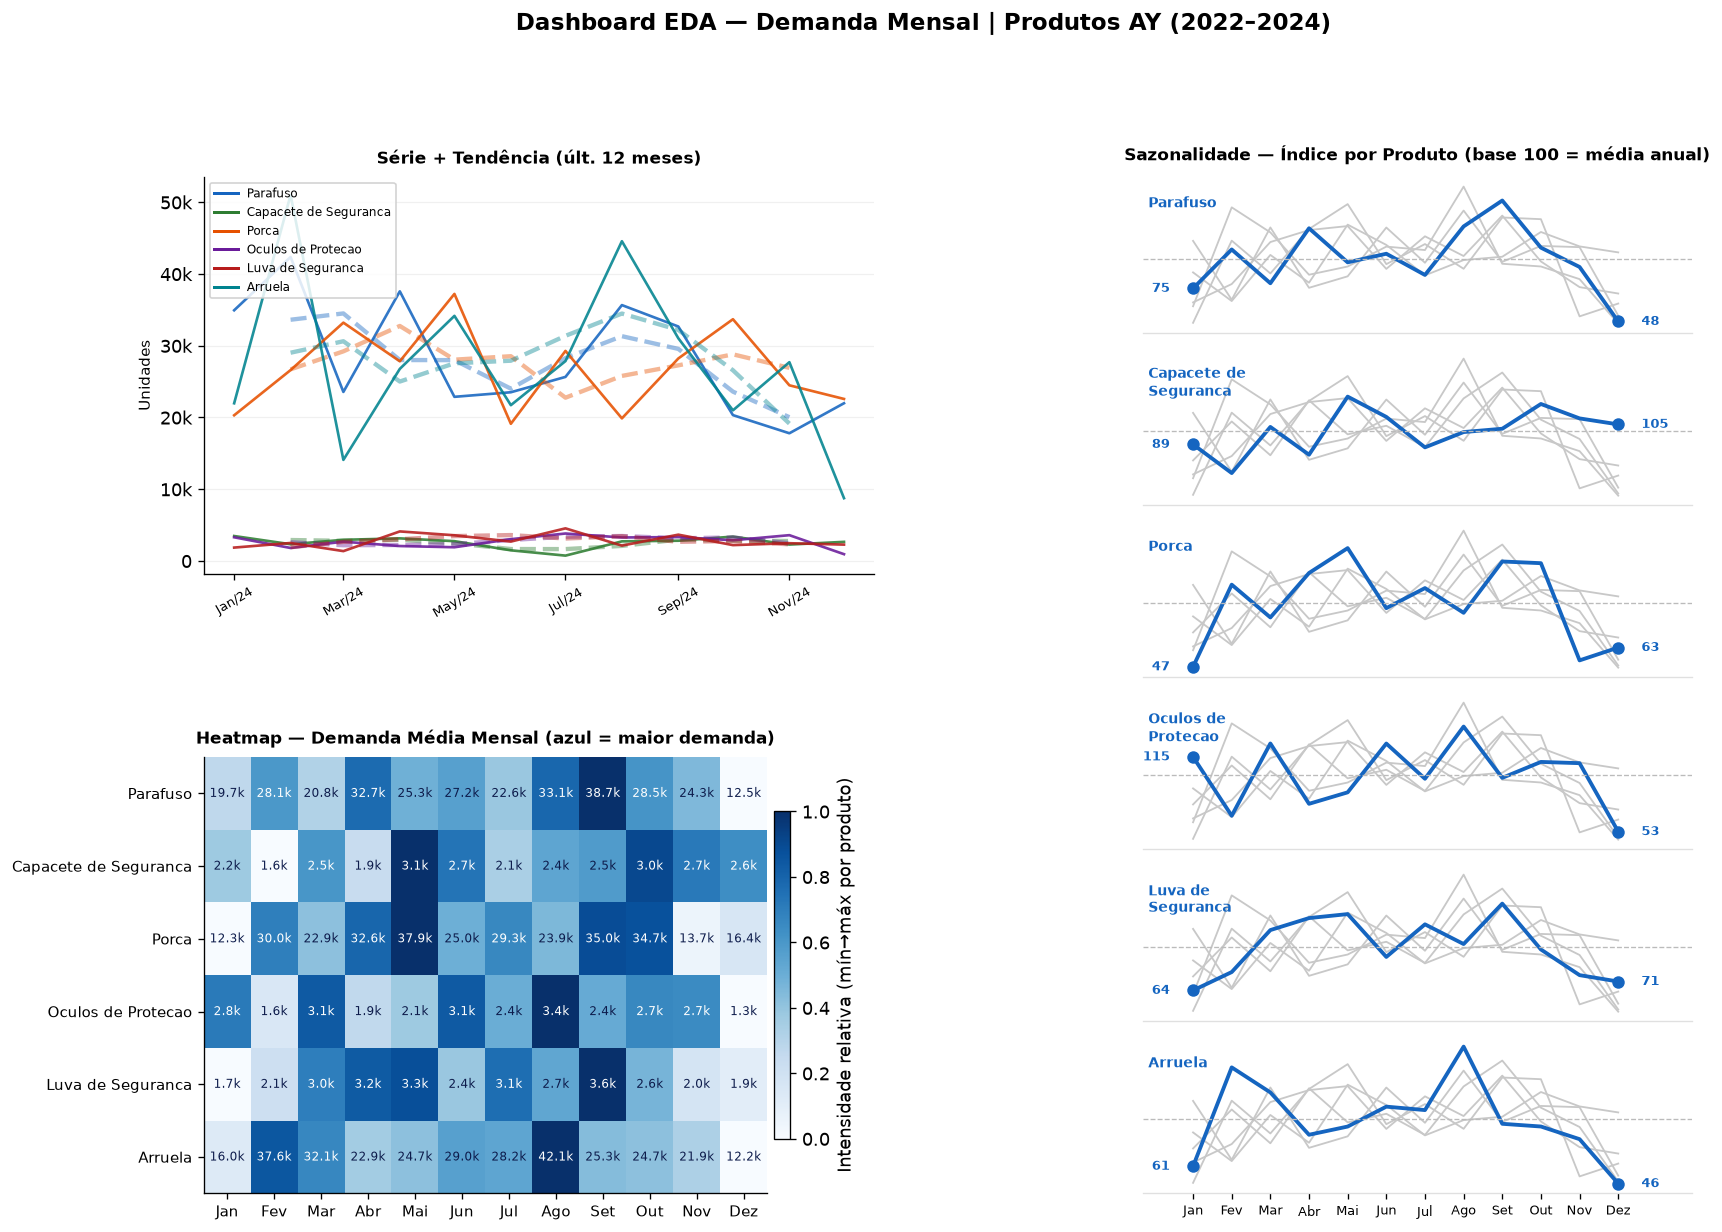

Dashboard EDA salvo: data/01_eda_dashboard.png


In [4]:
import textwrap
from matplotlib.gridspec import GridSpecFromSubplotSpec

# Cores atribuídas na ordem dos produtos AY (independe dos IDs da base)
PALETA = ['#1565C0', '#2E7D32', '#E65100', '#6A1B9A', '#B71C1C',
          '#00838F', '#F9A825', '#4E342E', '#AD1457', '#37474F']
CORES = {pid: PALETA[i % len(PALETA)] for i, pid in enumerate(IDS_AY)}

# Agregações base
df_ay_all  = df_raw[df_raw['id_produto'].isin(IDS_AY)].copy()
dem_mensal = df_ay_all.groupby(['id_produto', 'ano', 'mes'])['quantidade_pedida'].sum().reset_index()
sazon      = dem_mensal.groupby(['id_produto', 'mes'])['quantidade_pedida'].mean().reset_index()

MESES_ABREV = ['Jan','Fev','Mar','Abr','Mai','Jun','Jul','Ago','Set','Out','Nov','Dez']
N_P = len(IDS_AY)

# Pré-computa índices sazonais (base 100 = média anual do produto)
indices_sazon = {}
for pid in IDS_AY:
    sub  = sazon[sazon['id_produto'] == pid].set_index('mes').reindex(range(1, 13))
    med  = sub['quantidade_pedida'].mean()
    indices_sazon[pid] = (sub['quantidade_pedida'] / med * 100).values

y_min = min(v.min() for v in indices_sazon.values()) - 8
y_max = max(v.max() for v in indices_sazon.values()) + 8
x_vals = np.arange(12)

# Nome em até 2 linhas para caber no mini-chart
NOMES_CURTOS = {pid: '\n'.join(textwrap.wrap(NOMES[pid], 14)[:2]) for pid in IDS_AY}

fig = plt.figure(figsize=(16, 11))
fig.suptitle('Dashboard EDA — Demanda Mensal | Produtos AY (2022–2024)',
             fontsize=14, fontweight='bold', y=1.005)

gs_outer = fig.add_gridspec(1, 2, width_ratios=[1.1, 0.9], wspace=0.44)

# ── Coluna esquerda: Série (topo) + Heatmap (base) ───────────────────────
gs_left = GridSpecFromSubplotSpec(2, 1, subplot_spec=gs_outer[0],
                                  hspace=0.44, height_ratios=[1, 1.1])

# A: Série + Tendência
ax_a = fig.add_subplot(gs_left[0])
for pid in IDS_AY:
    s     = series[pid].iloc[-12:]
    trend = s.rolling(3, center=True).mean()
    ax_a.plot(s.index, s.values, color=CORES[pid], lw=1.6, alpha=0.88)
    ax_a.plot(trend.index, trend.values, color=CORES[pid], lw=2.6, ls='--', alpha=0.42)
ax_a.set_title('Série + Tendência (últ. 12 meses)', fontsize=10, fontweight='bold', pad=8)
ax_a.set_ylabel('Unidades', fontsize=9)
ax_a.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%b/%y'))
ax_a.tick_params(axis='x', rotation=30, labelsize=8)
ax_a.grid(axis='y', alpha=0.18, lw=0.7)
ax_a.yaxis.set_major_formatter(mticker.FuncFormatter(
    lambda v, _: f'{v/1000:.0f}k' if v >= 1000 else f'{v:.0f}'
))
handles_a = [plt.Line2D([0],[0], color=CORES[p], lw=1.8, label=NOMES[p][:22]) for p in IDS_AY]
ax_a.legend(handles=handles_a, fontsize=7, loc='upper left', framealpha=0.85)

# B: Heatmap
ax_b = fig.add_subplot(gs_left[1])
pivot_raw = (sazon
             .pivot_table(values='quantidade_pedida', index='id_produto',
                          columns='mes', aggfunc='mean')
             .reindex(index=IDS_AY, columns=range(1, 13)))
row_min   = pivot_raw.min(axis=1)
row_rng   = (pivot_raw.max(axis=1) - row_min).replace(0, 1)
pivot_norm = pivot_raw.subtract(row_min, axis=0).divide(row_rng, axis=0)

im = ax_b.imshow(pivot_norm.values, aspect='auto', cmap='Blues', vmin=0, vmax=1)
ax_b.set_xticks(range(12))
ax_b.set_xticklabels(MESES_ABREV, fontsize=9)
ax_b.set_yticks(range(N_P))
ax_b.set_yticklabels([NOMES[p][:24] for p in IDS_AY], fontsize=9)
ax_b.set_title('Heatmap — Demanda Média Mensal (azul = maior demanda)',
               fontsize=10, fontweight='bold', pad=8)
plt.colorbar(im, ax=ax_b, shrink=0.75, pad=0.01, label='Intensidade relativa (mín→máx por produto)')

for i in range(N_P):
    for j in range(12):
        v_raw  = pivot_raw.values[i, j]
        v_norm = pivot_norm.values[i, j]
        if not np.isnan(v_raw):
            txt = f'{v_raw/1000:.1f}k' if v_raw >= 1000 else f'{v_raw:.0f}'
            ax_b.text(j, i, txt, ha='center', va='center', fontsize=7,
                      color='white' if v_norm > 0.58 else '#0D1B4B')

# ── Coluna direita: mini-charts — spotlight por produto ────────────────
gs_right = GridSpecFromSubplotSpec(N_P, 1, subplot_spec=gs_outer[1], hspace=0.10)
AZUL  = '#1565C0'
CINZA = '#C8C8C8'

for k, pid_dest in enumerate(IDS_AY):
    ax = fig.add_subplot(gs_right[k])

    # Todas as outras linhas em cinza (contexto)
    for pid in IDS_AY:
        if pid != pid_dest:
            ax.plot(x_vals, indices_sazon[pid], color=CINZA, lw=1.1, zorder=1)

    # Linha destacada em azul
    idx = indices_sazon[pid_dest]
    ax.plot(x_vals, idx, color=AZUL, lw=2.3, zorder=2)
    ax.scatter([0, 11], [idx[0], idx[11]], color=AZUL, s=42, zorder=3)

    # Valores Jan e Dez na ponta da linha azul
    ax.text(-0.6, idx[0],  f'{idx[0]:.0f}',
            ha='right', va='center', fontsize=8, color=AZUL, fontweight='bold')
    ax.text(11.6, idx[11], f'{idx[11]:.0f}',
            ha='left',  va='center', fontsize=8, color=AZUL, fontweight='bold')

    # Linha de referência 100
    ax.axhline(100, color='#BBBBBB', lw=0.8, ls='--')

    # Nome do produto (canto superior esquerdo, dentro do chart)
    ax.text(0.01, 0.90, NOMES_CURTOS[pid_dest],
            transform=ax.transAxes, ha='left', va='top',
            fontsize=8.5, fontweight='bold', color=AZUL, clip_on=False,
            linespacing=1.3)

    # Meses: só no último mini-chart
    if k == N_P - 1:
        ax.set_xticks(x_vals)
        ax.set_xticklabels(MESES_ABREV, fontsize=7.5)
    else:
        ax.set_xticks([])

    ax.set_yticks([])
    ax.set_xlim(-1.3, 12.9)
    ax.set_ylim(y_min, y_max)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_color('#E0E0E0')

    if k == 0:
        ax.set_title('Sazonalidade — Índice por Produto (base 100 = média anual)',
                     fontsize=10, fontweight='bold', pad=10)

plt.savefig('data/01_eda_dashboard.png', bbox_inches='tight', dpi=120)
plt.show()
print('Dashboard EDA salvo: data/01_eda_dashboard.png')


## 2. Limpeza e Preparação da Série Temporal

- **O que será feito:** para cada uma das 6 séries mensais construídas acima, verificamos (a) *gaps* de calendário — meses sem nenhum pedido registrado, que viram `NaN` após o `.asfreq('MS')` —, (b) outliers pela regra de Tukey (1.5×IQR) e (c) confirmamos que a frequência é mensal e regular.
- **Por que importa:** a base `base_tratada.csv` já foi validada no nível de pedido na Etapa 2 do projeto (sem nulos, sem duplicatas), mas isso não garante que a **série agregada mensal** esteja completa. Um gap não tratado quebra a sazonalidade da qual Holt-Winters/SARIMA dependem para estimar parâmetros; um outlier não identificado pode inflar o erro do walk-forward sem que se saiba a causa.
- **Como interpretar o resultado:** a tabela abaixo mostra, por produto, quantos meses têm dado, quantos gaps foram encontrados (e preenchidos por interpolação temporal) e quantos outliers existem fora dos limites de Tukey. **Outliers não são removidos automaticamente** — em séries de demanda, um pico ou vale extremo costuma refletir um evento real de negócio (promoção, ruptura de estoque, pedido consolidado), não um erro de medição. Eles ficam sinalizados no gráfico de dispersão abaixo para leitura visual; qualquer tratamento (capping, remoção) deve ser decidido caso a caso, não por regra cega.


In [5]:
def diagnosticar_serie(s, iqr_k=1.5):
    """Gaps de calendário + outliers pela regra de Tukey (1.5xIQR)."""
    gaps = s[s.isna()]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - iqr_k * iqr, q3 + iqr_k * iqr
    outliers = s[(s < lim_inf) | (s > lim_sup)]
    return gaps, outliers, (lim_inf, lim_sup)


diagnostico_rows = []
series_limpa = {}
limites_iqr = {}

for pid, s in series.items():
    gaps, outliers, (lim_inf, lim_sup) = diagnosticar_serie(s)
    limites_iqr[pid] = (lim_inf, lim_sup)

    s_limpa = s.copy()
    if gaps.shape[0] > 0:
        s_limpa = s_limpa.interpolate(method='time')
    series_limpa[pid] = s_limpa

    diagnostico_rows.append({
        'Produto':        NOMES[pid],
        'Meses c/ dado':  int(s.notna().sum()),
        'Gaps (NaN)':     int(gaps.shape[0]),
        'Outliers (IQR)': int(outliers.shape[0]),
        'Limite inf.':    round(lim_inf, 0),
        'Limite sup.':    round(lim_sup, 0),
    })

# A partir daqui 'series' referencia a versão validada (gaps preenchidos,
# outliers preservados) -- todo o restante do notebook usa esta versão.
series = series_limpa

df_diag = pd.DataFrame(diagnostico_rows)
print(f"Frequência confirmada: {list(series.values())[0].index.freqstr} (mensal, sem buracos)\n")
print(df_diag.to_string(index=False))


Frequência confirmada: MS (mensal, sem buracos)

              Produto  Meses c/ dado  Gaps (NaN)  Outliers (IQR)  Limite inf.  Limite sup.
             Parafuso             36           0               1       4325.0      50033.0
Capacete de Seguranca             36           0               0        -17.0       4843.0
                Porca             36           0               1      -4331.0      56523.0
   Oculos de Protecao             36           0               0       -995.0       5844.0
    Luva de Seguranca             36           0               0        251.0       4890.0
              Arruela             36           0               0        658.0      53073.0


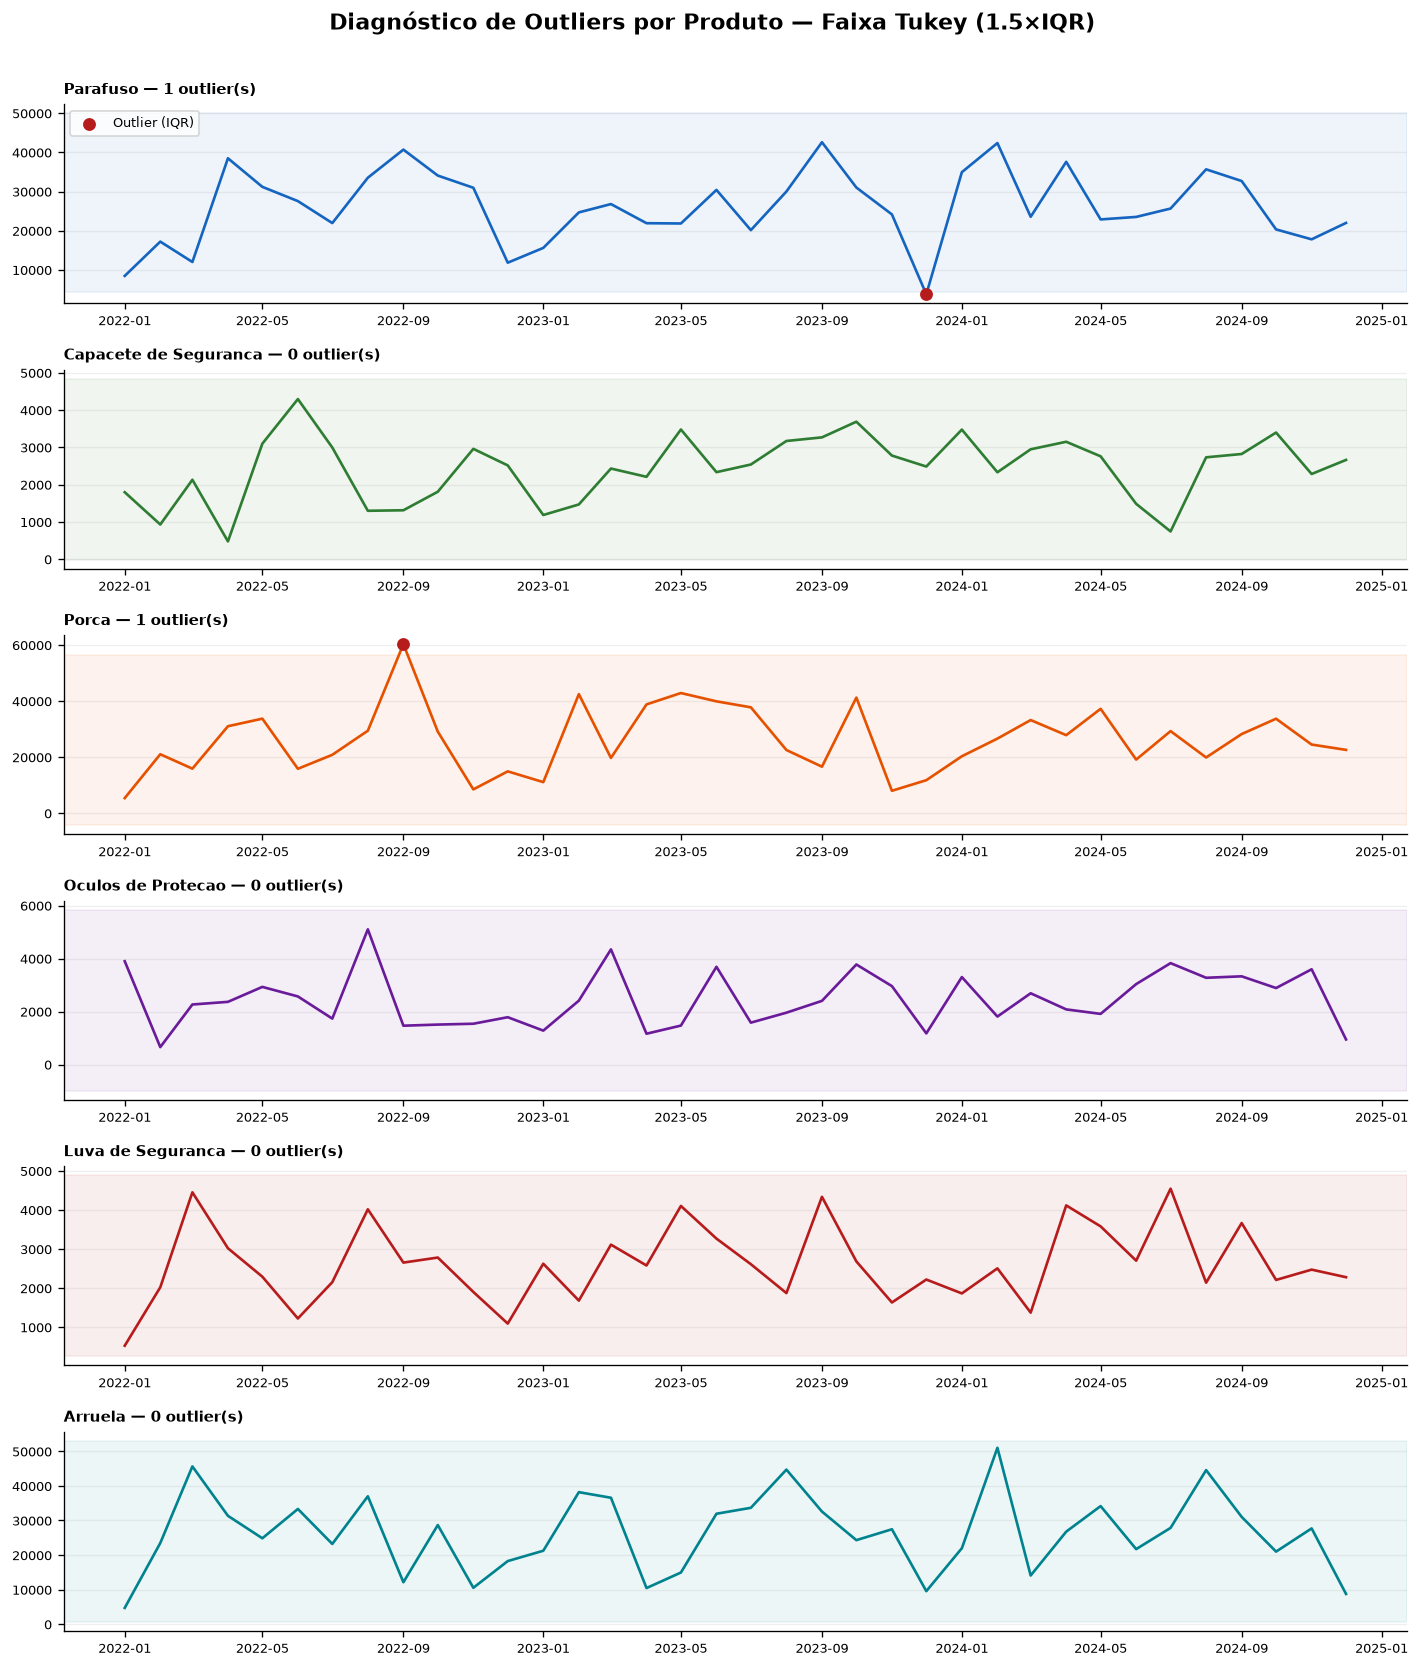

In [6]:
fig, axes = plt.subplots(len(IDS_AY), 1, figsize=(12, 2.3 * len(IDS_AY)), sharex=False)

for ax, pid in zip(axes, IDS_AY):
    s = series[pid]
    lim_inf, lim_sup = limites_iqr[pid]
    out_mask = (s < lim_inf) | (s > lim_sup)

    ax.plot(s.index, s.values, color=CORES[pid], lw=1.6)
    ax.axhspan(lim_inf, lim_sup, color=CORES[pid], alpha=0.07)
    ax.scatter(s.index[out_mask], s.values[out_mask], color='#B71C1C', s=45,
               zorder=3, label='Outlier (IQR)')
    ax.set_title(f'{NOMES[pid]} — {int(out_mask.sum())} outlier(s)',
                 fontsize=9, fontweight='bold', loc='left')
    ax.tick_params(labelsize=8)
    ax.grid(axis='y', alpha=0.2)

axes[0].legend(fontsize=8, loc='upper left')
fig.suptitle('Diagnóstico de Outliers por Produto — Faixa Tukey (1.5×IQR)',
             fontsize=13, fontweight='bold', y=1.005)
plt.tight_layout()
plt.savefig('data/02b_diagnostico_outliers_AY.png', bbox_inches='tight', dpi=120)
plt.show()


### Conclusão — Gaps e Outliers

- **Gaps:** todas as 6 séries têm 36/36 meses com dado e 0 gaps de calendário — não houve necessidade de interpolação em nenhum produto.
- **Outliers:** apenas dois pontos fora da faixa de Tukey — um vale em **Parafuso** (dez/2023: 3.771 un., abaixo do limite inferior de 4.325) e um pico em **Porca** (set/2022: 60.307 un., acima do limite superior de 56.523). Ambos foram preservados intencionalmente na série por representarem variações reais de demanda, não erros de dado. Os outros quatro produtos não têm outliers.
- **Validação:** a base mensal agregada está completa e regular (frequência `MS` confirmada, sem buracos), condição mínima para que Holt-Winters, SARIMA e XGBoost consigam estimar sazonalidade e tendência de forma confiável. **Está validado para seguir com a análise temporal.**

## 3. Análise Exploratória — Decomposição da Série

- **O que será feito:** decompomos cada série mensal em três componentes — **tendência** (movimento de longo prazo), **sazonalidade** (padrão que se repete a cada 12 meses) e **resíduo** (o que sobra depois de remover tendência e sazonalidade) — usando `seasonal_decompose` (modelo aditivo, período 12).
- **Por que importa:** essa é a base conceitual para os modelos já usados na Seção 6 (Holt-Winters e SARIMA), que assumem explicitamente uma estrutura de tendência + sazonalidade aditiva. Ver esses componentes de forma isolada — sem o ruído misturado — confirma se essa premissa é razoável para os 6 produtos AY, ou se algum deles foge do padrão (ex.: sazonalidade que muda de amplitude ao longo dos anos, o que pediria um modelo multiplicativo).
- **Como interpretar o resultado:** tendência com inclinação constante indica crescimento/queda estrutural; sazonalidade com formato repetido ano a ano confirma o padrão anual já visto no heatmap da Seção 1; resíduo **sem padrão visível e oscilando em torno de zero** indica que tendência + sazonalidade capturaram a maior parte do sinal — se o resíduo ainda mostrar ciclos, os modelos sazonais podem não ser suficientes para aquele produto.


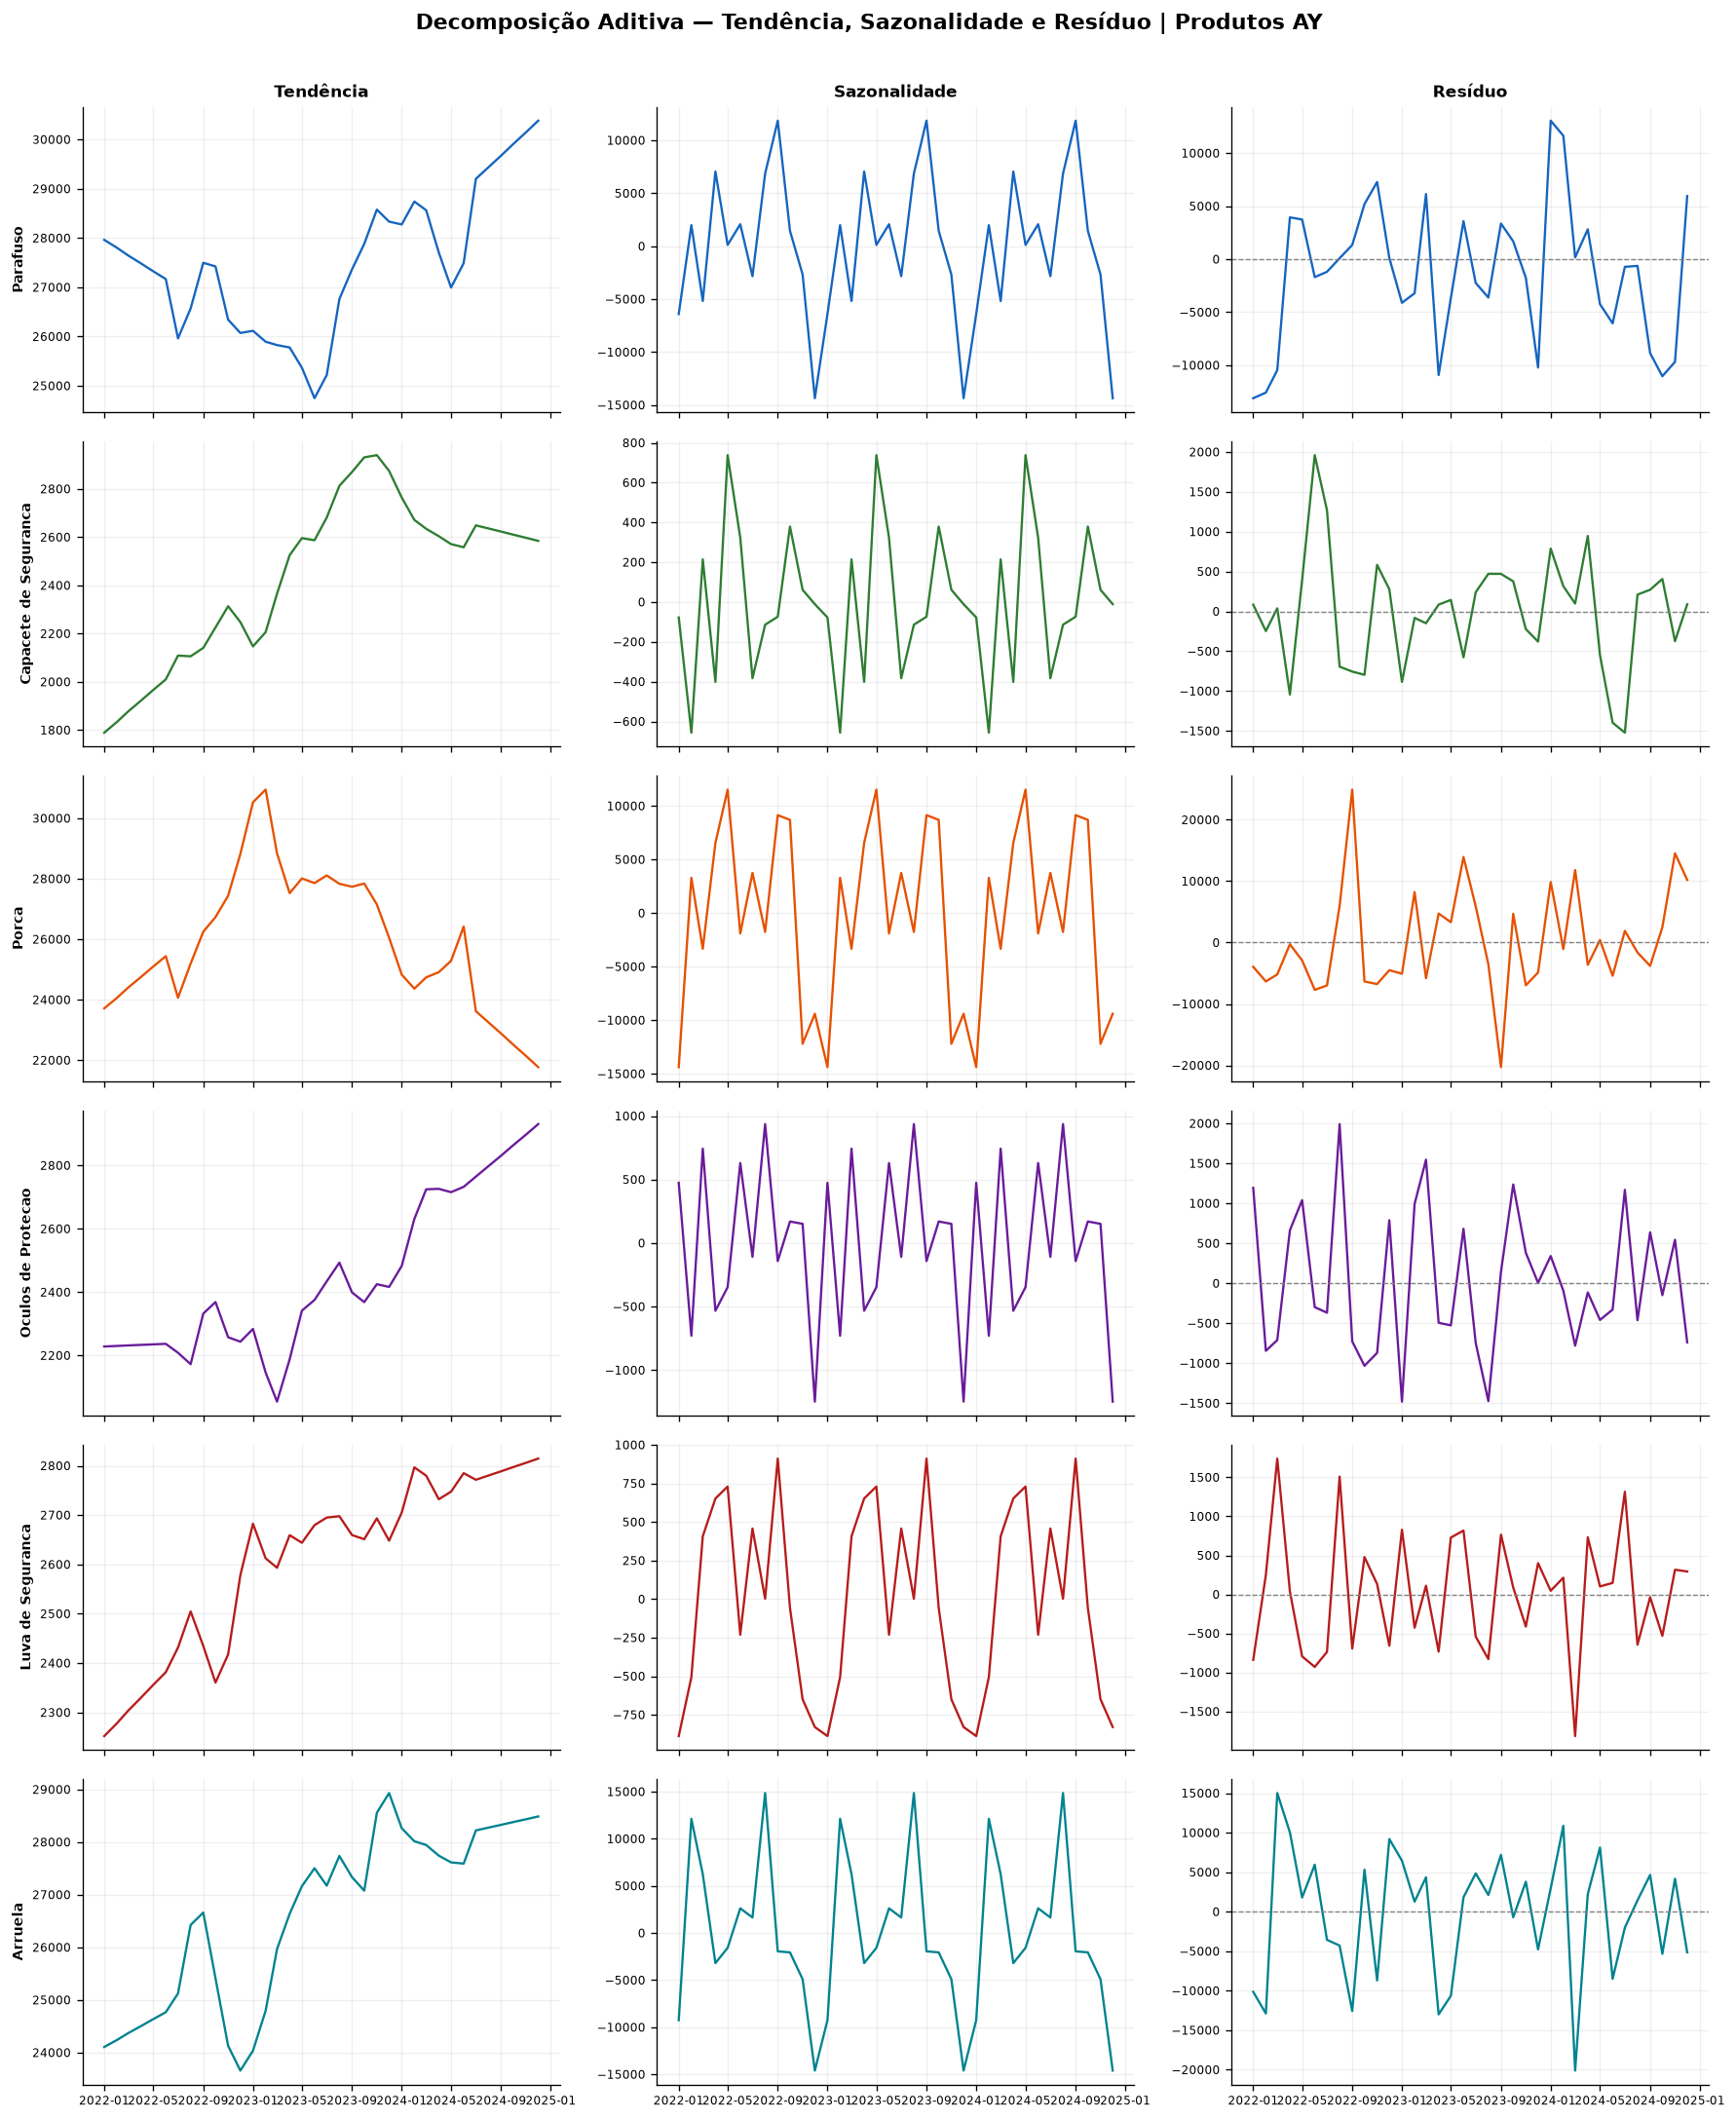

In [7]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposicoes = {
    pid: seasonal_decompose(series[pid], model='additive', period=12, extrapolate_trend='freq')
    for pid in IDS_AY
}

COMPONENTES = [('trend', 'Tendência'), ('seasonal', 'Sazonalidade'), ('resid', 'Resíduo')]
fig, axes = plt.subplots(len(IDS_AY), 3, figsize=(15, 3 * len(IDS_AY)), sharex=True)

for i, pid in enumerate(IDS_AY):
    dec = decomposicoes[pid]
    for j, (attr, titulo) in enumerate(COMPONENTES):
        ax = axes[i, j]
        comp = getattr(dec, attr)
        ax.plot(comp.index, comp.values, color=CORES[pid], lw=1.4)
        if attr == 'resid':
            ax.axhline(0, color='gray', lw=0.8, ls='--')
        if j == 0:
            ax.set_ylabel(NOMES_CURTOS[pid].replace('\n', ' '), fontsize=8.5, fontweight='bold')
        ax.tick_params(labelsize=7)
        ax.grid(alpha=0.2)

axes[0, 0].set_title('Tendência', fontsize=10, fontweight='bold')
axes[0, 1].set_title('Sazonalidade', fontsize=10, fontweight='bold')
axes[0, 2].set_title('Resíduo', fontsize=10, fontweight='bold')

fig.suptitle('Decomposição Aditiva — Tendência, Sazonalidade e Resíduo | Produtos AY',
             fontsize=13, fontweight='bold', y=1.005)
plt.tight_layout()
plt.savefig('data/03_decomposicao_AY.png', bbox_inches='tight', dpi=120)
plt.show()


### Conclusão — Decomposição da Série

- **Tendência:** suave e sem quebras estruturais abruptas — leve alta em 5 dos 6 produtos (mais visível nos três EPIs) e leve queda em Porca.
- **Sazonalidade:** a amplitude do componente sazonal é grande em relação ao nível da série (nos Fixadores, da ordem de 26–29 mil un. entre o melhor e o pior mês). Vale lembrar que o `seasonal_decompose` impõe o mesmo padrão a todos os anos — com apenas 3 ciclos, esse padrão é uma estimativa pouco robusta, não uma confirmação de sazonalidade estável.
- **Resíduo:** oscila em torno de zero, mas é **grande**: responde por cerca de 50% a 67% da variância de cada série. Tendência + sazonalidade explicam, portanto, só uma parte do sinal — o restante é ruído que nenhum modelo sazonal vai capturar.
- **Validação:** não há evidência contra a estrutura **aditiva** usada por Holt-Winters (`trend='add', seasonal='add'`) e pelo SARIMA, mas o peso do resíduo antecipa **erros de previsão elevados** na etapa de modelagem. **Está validado para seguir, com essa ressalva.**

## 4. Teste de Estacionariedade (Dickey-Fuller Aumentado)

- **O que será feito:** aplicamos o teste ADF (Augmented Dickey-Fuller) em cada série no nível original e, em seguida, na série diferenciada (`diff(1)`), para checar formalmente se a demanda mensal é estacionária (média e variância constantes no tempo).
- **Por que importa:** o SARIMA já é usado na Seção 6 com `order=(1,1,1)` — ou seja, **já assume 1 diferenciação (d=1)** para tornar a série estacionária. Este teste existe para **validar essa premissa com evidência estatística**, em vez de aceitá-la apenas por convenção. Holt-Winters não exige estacionariedade, mas o diagnóstico ainda ajuda a entender a natureza de cada série.
- **Como interpretar o resultado:** a hipótese nula (H0) do teste é "a série tem raiz unitária" (não é estacionária). **p-valor < 0.05** → rejeita H0 → série estacionária. Se a série original não for estacionária mas a diferenciada for, isso confirma que `d=1` (já usado no SARIMA) é a escolha correta; se mesmo diferenciada ainda não for estacionária, seria um sinal de que o modelo precisaria de `d=2` ou de diferenciação sazonal adicional.


In [8]:
from statsmodels.tsa.stattools import adfuller

def teste_adf(s):
    stat, pval, *_ = adfuller(s.dropna(), autolag='AIC')
    return stat, pval

adf_rows = []
for pid in IDS_AY:
    s = series[pid]
    stat_niv, p_niv = teste_adf(s)
    stat_dif, p_dif = teste_adf(s.diff())

    adf_rows.append({
        'Produto':               NOMES[pid],
        'ADF (nível)':           round(stat_niv, 3),
        'p-valor (nível)':       round(p_niv, 4),
        'Estacionária?':         'Sim' if p_niv < 0.05 else 'Não',
        'ADF (diff. 1)':         round(stat_dif, 3),
        'p-valor (diff. 1)':     round(p_dif, 4),
        'Estacionária (diff)?':  'Sim' if p_dif < 0.05 else 'Não',
    })

df_adf = pd.DataFrame(adf_rows)
print('Teste de Dickey-Fuller Aumentado — H0: série tem raiz unitária (não estacionária)\n')
print(df_adf.to_string(index=False))


Teste de Dickey-Fuller Aumentado — H0: série tem raiz unitária (não estacionária)

              Produto  ADF (nível)  p-valor (nível) Estacionária?  ADF (diff. 1)  p-valor (diff. 1) Estacionária (diff)?
             Parafuso       -1.388           0.5881           Não         -3.913             0.0019                  Sim
Capacete de Seguranca       -4.190           0.0007           Sim         -5.775             0.0000                  Sim
                Porca       -5.296           0.0000           Sim         -8.522             0.0000                  Sim
   Oculos de Protecao       -6.913           0.0000           Sim         -4.492             0.0002                  Sim
    Luva de Seguranca       -6.083           0.0000           Sim         -6.619             0.0000                  Sim
              Arruela       -3.948           0.0017           Sim         -3.300             0.0149                  Sim


### Conclusão — Estacionariedade (ADF)

- Capacete de Segurança, Porca, Óculos de Proteção, Luva de Segurança e Arruela já são estacionários no nível (p < 0,05).
- Apenas **Parafuso** não é estacionário no nível (p = 0,588), mas passa a ser após uma diferenciação (`diff(1)`, p = 0,002).
- **Validação:** o `d=1` utilizado no SARIMA (`order=(1,1,1)`) é a escolha estatisticamente necessária para Parafuso. Para as outras cinco séries ele não é exigido pelo teste — é uma simplificação (configuração única para todos os produtos) que traz risco de *over-differencing*, um custo menor do que modelar uma série não estacionária, mas que vale testar com `d=0` em uma evolução do modelo. **Está validado para seguir com a previsão.**

## 5. Autocorrelação — ACF e PACF

- **O que será feito:** plotamos a função de autocorrelação (ACF) e a autocorrelação parcial (PACF) de cada série — usando a versão diferenciada quando o teste ADF acima indicou que o nível original não é estacionário — até ~17 defasagens (o teste de Yule-Walker usado na PACF só é estável até 50% do tamanho da amostra, então o número de lags é limitado automaticamente).
- **Por que importa:** ACF e PACF são o que embasa tecnicamente a escolha dos parâmetros `(p, d, q)(P, D, Q, 12)` do SARIMA — aqui usado como `(1,1,1)(1,1,0,12)` na Seção 6. Em vez de aceitar essa configuração apenas por convenção, este diagnóstico mostra se ela é consistente com o comportamento real de cada série AY.
- **Como interpretar o resultado:** um corte abrupto na **PACF** após a defasagem *p* sugere um termo AR(*p*); um corte abrupto na **ACF** após a defasagem *q* sugere um termo MA(*q*). Picos recorrentes na defasagem 12 (linha tracejada) em qualquer um dos dois gráficos confirmam a sazonalidade anual e justificam o componente sazonal `(P,D,Q,12)` do modelo. A área sombreada é o intervalo de confiança de 95% — barras dentro dela não são estatisticamente diferentes de zero.


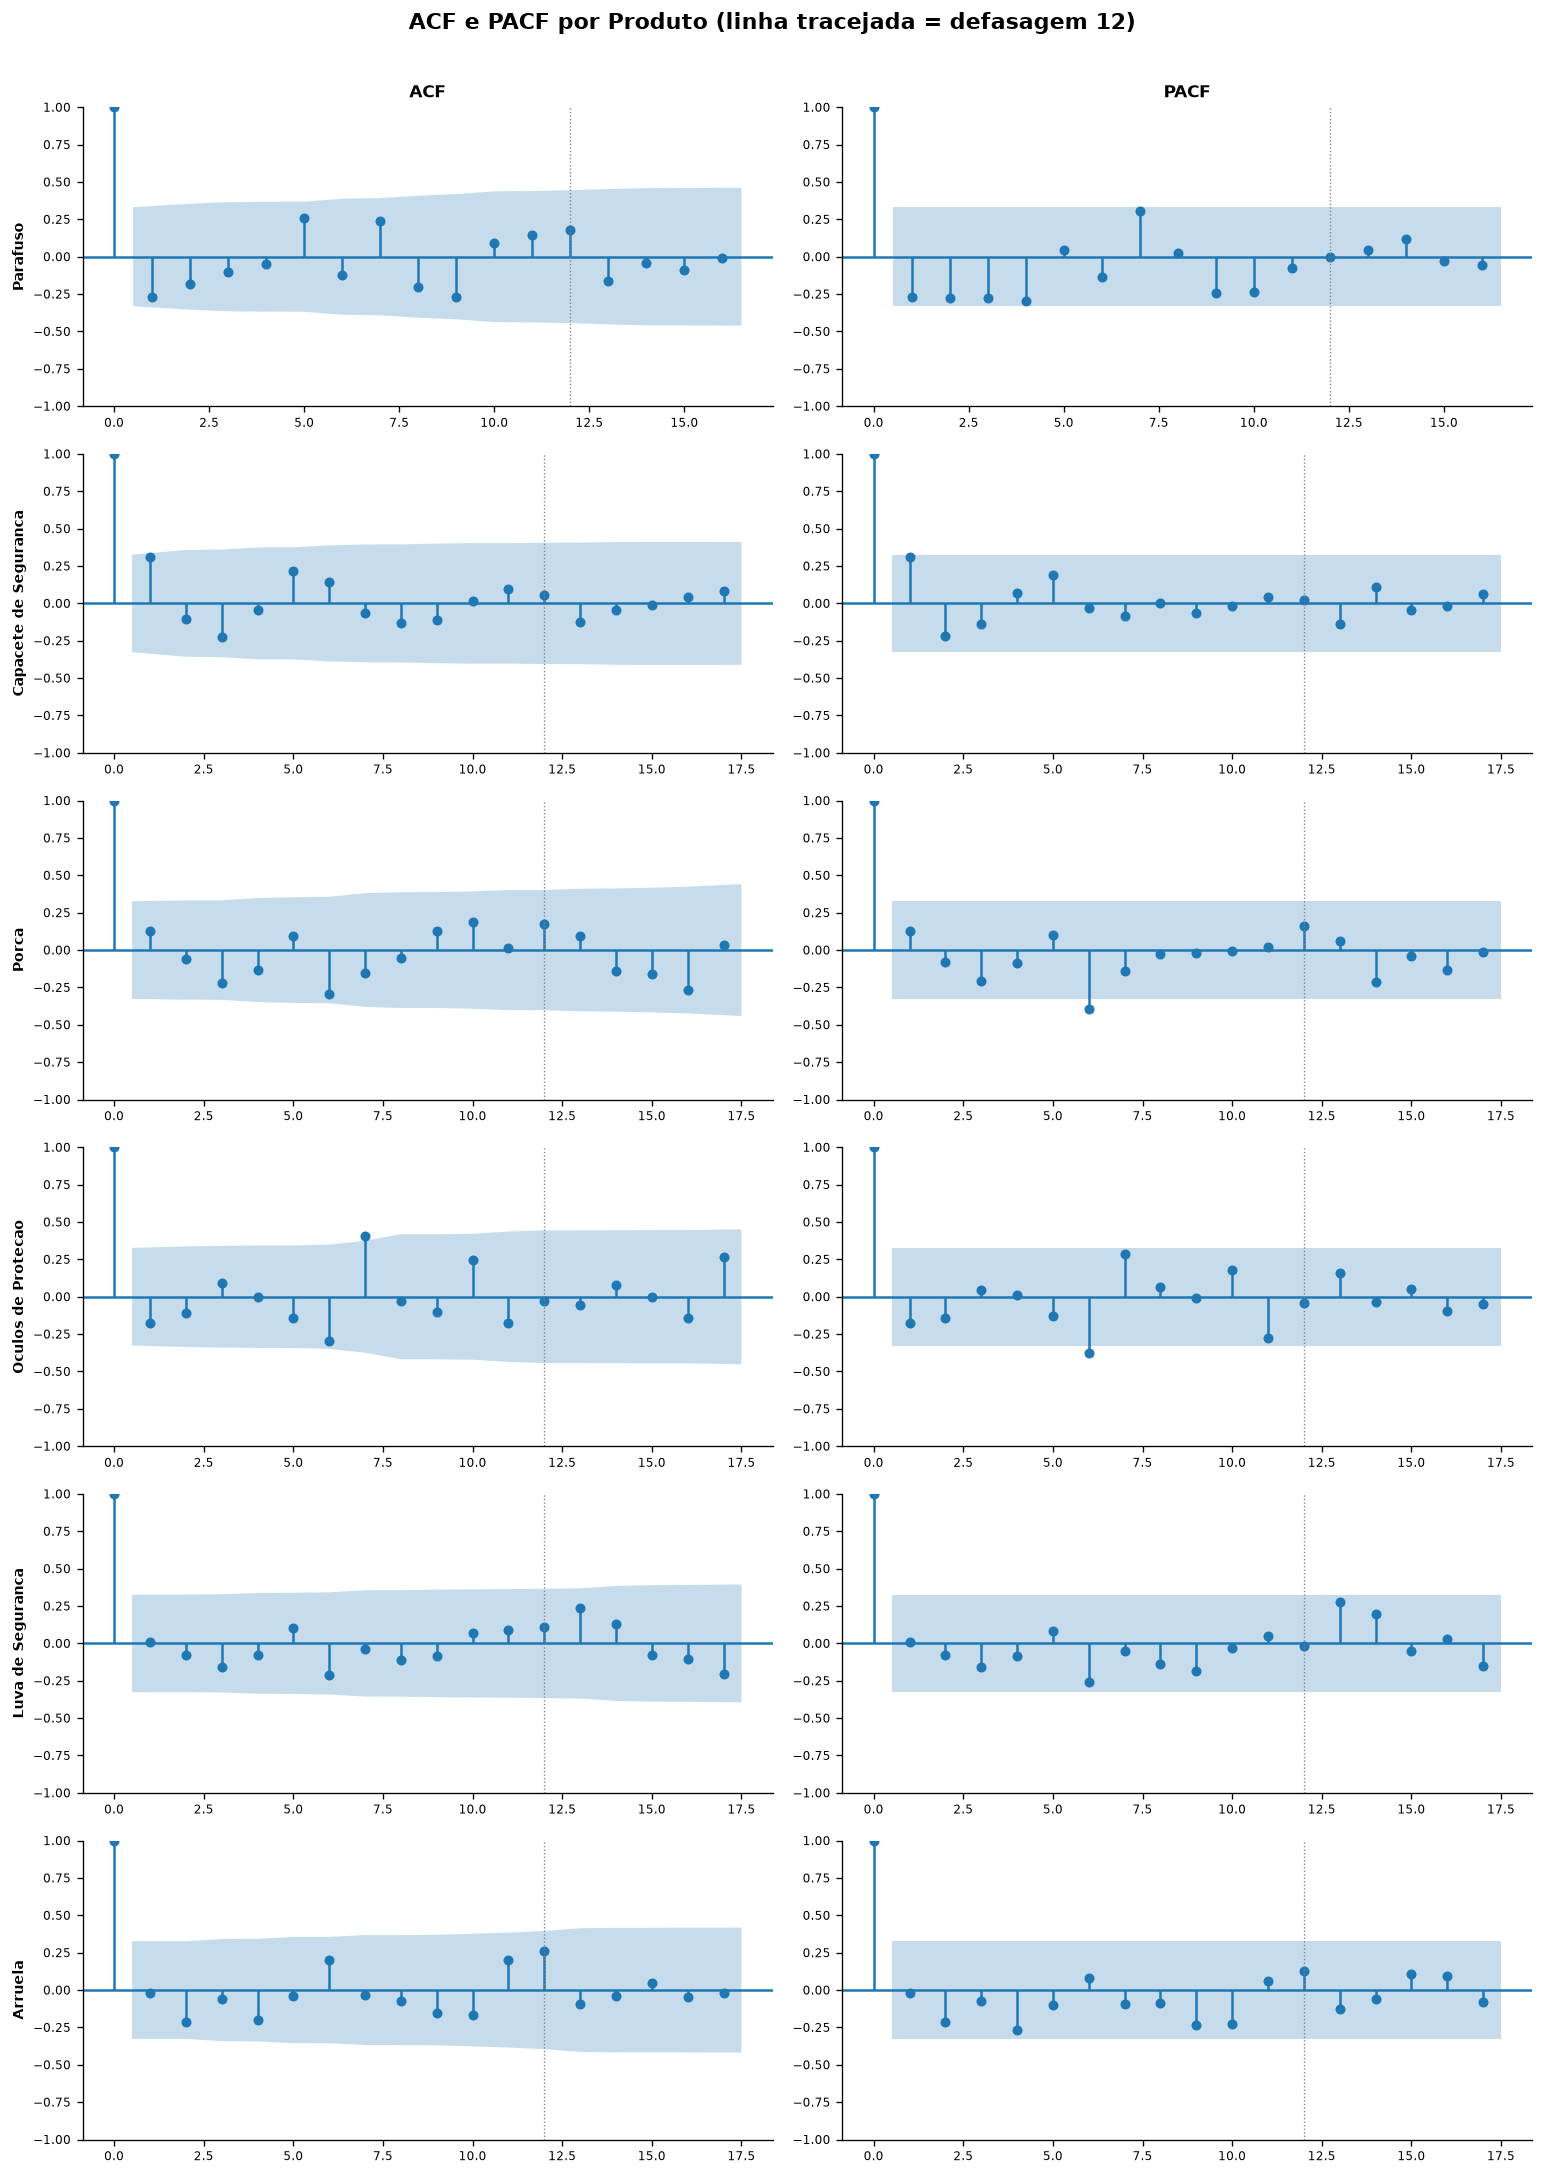

In [9]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(len(IDS_AY), 2, figsize=(13, 3 * len(IDS_AY)))

for i, pid in enumerate(IDS_AY):
    s_ref = series[pid]
    estacionaria = df_adf.loc[df_adf['Produto'] == NOMES[pid], 'Estacionária?'].iloc[0] == 'Sim'
    s_plot = s_ref if estacionaria else s_ref.diff().dropna()

    # PACF (Yule-Walker) só é estável até ~50% do tamanho da amostra
    n_lags = min(24, len(s_plot) // 2 - 1)
    plot_acf(s_plot, ax=axes[i, 0], lags=n_lags, title='')
    plot_pacf(s_plot, ax=axes[i, 1], lags=n_lags, method='ywm', title='')

    axes[i, 0].set_ylabel(NOMES_CURTOS[pid].replace('\n', ' '), fontsize=8.5, fontweight='bold')
    for ax in axes[i]:
        ax.axvline(12, color='gray', lw=0.8, ls=':')
        ax.tick_params(labelsize=7)

axes[0, 0].set_title('ACF', fontsize=10, fontweight='bold')
axes[0, 1].set_title('PACF', fontsize=10, fontweight='bold')

fig.suptitle('ACF e PACF por Produto (linha tracejada = defasagem 12)',
             fontsize=13, fontweight='bold', y=1.005)
plt.tight_layout()
plt.savefig('data/04_acf_pacf_AY.png', bbox_inches='tight', dpi=120)
plt.show()


### Conclusão — Autocorrelação (ACF/PACF)

- **Nenhum produto apresenta pico estatisticamente significativo na defasagem 12** (linha tracejada): as autocorrelações nesse lag ficam entre −0,03 e +0,26, dentro do intervalo de confiança de 95%. Com 36 observações, a sazonalidade anual sugerida pela decomposição **não se confirma estatisticamente** — o componente `(P,D,Q,12)` do SARIMA é mantido como hipótese de negócio, não como evidência dos dados.
- As autocorrelações de curto prazo também são fracas: quase todas as barras ficam dentro da área sombreada, com exceções pontuais (defasagem 6 na PACF de Porca; defasagens 6–7 em Óculos de Proteção). As séries se comportam de forma próxima a um ruído em torno da média.
- **Validação:** não há estrutura de autocorrelação que contradiga um modelo de baixa ordem, e a ordem fixa `(1,1)` é uma simplificação aceitável. Mas a pouca memória das séries indica que **os ganhos de qualquer modelo sobre uma média simples tendem a ser limitados** — o que deve ser lido junto com os MAPEs da Seção 6. **Está validado para seguir com a etapa de previsão de demanda (Seção 6), com essa ressalva.**

## 6. Modelagem e Validação (Walk-Forward)

Cada modelo é treinado nos dados até o mês `t` e prevê `t+1`. O processo avança 6 vezes (últimos 6 meses do dataset) para gerar métricas reais de erro sem vazamento de informação futura.


In [10]:
def calcular_metricas(real, pred, nome):
    real = np.array(real, dtype=float)
    pred = np.array(pred, dtype=float)
    mape = np.mean(np.abs((real - pred) / np.where(real == 0, 1, real))) * 100
    mae  = mean_absolute_error(real, pred)
    rmse = np.sqrt(mean_squared_error(real, pred))
    return {
        'Modelo':   nome,
        'MAPE (%)': round(mape, 2),
        'MAE':      round(mae, 0),
        'RMSE':     round(rmse, 0),
    }


def walk_forward_validation(serie, model_fn, n_test):
    reais, preds = [], []
    n = len(serie)
    for i in range(n_test, 0, -1):
        train = serie.iloc[: n - i]
        real  = float(serie.iloc[n - i])
        try:
            pred = model_fn(train)
            reais.append(real)
            preds.append(max(0.0, float(pred)))
        except Exception:
            pass
    return np.array(reais), np.array(preds)


Testando modelos:


In [11]:
# Holt-Winters (ETS) — tendencia + sazonalidade aditiva
def modelo_ets(train):
    if len(train) < 24:
        raise ValueError('ETS requer >= 24 pontos')
    m = ExponentialSmoothing(
        train, trend='add', seasonal='add', seasonal_periods=12
    )
    return float(m.fit(optimized=True).forecast(1).iloc[0])


# SARIMA(1,1,1)(1,1,0,12) — modelo classico sazonal
def modelo_sarima(train):
    if len(train) < 24:
        raise ValueError('SARIMA requer >= 24 pontos')
    m = SARIMAX(
        train,
        order=(1, 1, 1),
        seasonal_order=(1, 1, 0, 12),
        enforce_stationarity=False,
        enforce_invertibility=False,
    )
    return float(m.fit(disp=False).forecast(1).iloc[0])


# XGBoost — Gradient Boosting com features de lag e media movel
def modelo_xgb(train):
    if len(train) < 15:
        raise ValueError('XGB requer >= 15 pontos')
    df_l = pd.DataFrame({'y': train.values})
    for lag in [1, 2, 3, 6, 12]:
        df_l[f'lag{lag}'] = df_l['y'].shift(lag)
    df_l['roll3'] = df_l['y'].shift(1).rolling(3).mean()
    df_l['roll6'] = df_l['y'].shift(1).rolling(6).mean()
    df_l = df_l.dropna()
    X, y = df_l.drop('y', axis=1), df_l['y']
    gb = GradientBoostingRegressor(
        n_estimators=300, max_depth=3, learning_rate=0.05,
        subsample=0.8, min_samples_leaf=2, random_state=42,
    )
    gb.fit(X, y)
    v = train.values
    feats = {
        'lag1':  v[-1],
        'lag2':  v[-2],
        'lag3':  v[-3],
        'lag6':  v[-6]  if len(v) >= 6  else v[-1],
        'lag12': v[-12] if len(v) >= 12 else v[-1],
        'roll3': np.mean(v[-3:]),
        'roll6': np.mean(v[-6:]) if len(v) >= 6 else np.mean(v),
    }
    return float(gb.predict(pd.DataFrame([feats]))[0])


# Prophet (Meta) — tendencia com changepoints + sazonalidade
def modelo_prophet(train):
    if not PROPHET_OK:
        raise ImportError('Prophet nao instalado')
    df_p = pd.DataFrame({'ds': train.index, 'y': train.values.astype(float)})
    m = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=False,
        daily_seasonality=False,
        seasonality_mode='additive',
        changepoint_prior_scale=0.1,
    )
    m.fit(df_p)
    future = m.make_future_dataframe(periods=1, freq='MS')
    return float(m.predict(future).iloc[-1]['yhat'])


MODELOS = {
    'Holt-Winters': modelo_ets,
    'SARIMA':       modelo_sarima,
    'XGBoost':      modelo_xgb,
}
if PROPHET_OK:
    MODELOS['Prophet'] = modelo_prophet

print(f'Modelos ativos: {list(MODELOS.keys())}')


Modelos ativos: ['Holt-Winters', 'SARIMA', 'XGBoost', 'Prophet']


In [12]:
resultados_por_produto = {}

for pid, serie in series.items():
    print(f'\n--- {pid}  {NOMES[pid]} ---')
    rows = []
    for nome_mod, fn in MODELOS.items():
        try:
            yr, yp = walk_forward_validation(serie, fn, N_TEST)
            if len(yr) > 0:
                m = calcular_metricas(yr, yp, nome_mod)
                rows.append(m)
                print(f"  {nome_mod:<16} MAPE={m['MAPE (%)']:5.2f}  "
                      f"MAE={m['MAE']:>8,.0f}  RMSE={m['RMSE']:>8,.0f}")
        except Exception as e:
            print(f'  {nome_mod:<16} ERRO: {e}')
    df_res = pd.DataFrame(rows).sort_values('MAPE (%)').reset_index(drop=True)
    resultados_por_produto[pid] = df_res



--- P01  Parafuso ---
  Holt-Winters     MAPE=39.86  MAE=   8,728  RMSE=  10,059
  SARIMA           MAPE=29.91  MAE=   7,372  RMSE=  10,061


23:07:41 - cmdstanpy - INFO - Chain [1] start processing
23:07:41 - cmdstanpy - INFO - Chain [1] done processing


  XGBoost          MAPE=30.77  MAE=   7,006  RMSE=   8,656


23:07:41 - cmdstanpy - INFO - Chain [1] start processing
23:07:41 - cmdstanpy - INFO - Chain [1] done processing
23:07:42 - cmdstanpy - INFO - Chain [1] start processing
23:07:42 - cmdstanpy - INFO - Chain [1] done processing
23:07:42 - cmdstanpy - INFO - Chain [1] start processing
23:07:42 - cmdstanpy - INFO - Chain [1] done processing
23:07:42 - cmdstanpy - INFO - Chain [1] start processing
23:07:42 - cmdstanpy - INFO - Chain [1] done processing
23:07:42 - cmdstanpy - INFO - Chain [1] start processing
23:07:42 - cmdstanpy - INFO - Chain [1] done processing


  Prophet          MAPE=60.40  MAE=  13,719  RMSE=  17,859

--- P07  Capacete de Seguranca ---
  Holt-Winters     MAPE=70.02  MAE=     724  RMSE=   1,152
  SARIMA           MAPE=49.63  MAE=     613  RMSE=     799


...

  Prophet          MAPE=84.30  MAE=   2,304  RMSE=   2,839

--- P03  Arruela ---
  Holt-Winters     MAPE=44.26  MAE=   7,776  RMSE=   9,209
  SARIMA           MAPE=23.61  MAE=   5,668  RMSE=   7,375


23:07:51 - cmdstanpy - INFO - Chain [1] start processing
23:07:51 - cmdstanpy - INFO - Chain [1] done processing


  XGBoost          MAPE=53.63  MAE=   7,902  RMSE=  10,105


23:07:51 - cmdstanpy - INFO - Chain [1] start processing
23:07:51 - cmdstanpy - INFO - Chain [1] done processing
23:07:51 - cmdstanpy - INFO - Chain [1] start processing
23:07:51 - cmdstanpy - INFO - Chain [1] done processing
23:07:51 - cmdstanpy - INFO - Chain [1] start processing
23:07:51 - cmdstanpy - INFO - Chain [1] done processing
23:07:52 - cmdstanpy - INFO - Chain [1] start processing
23:07:52 - cmdstanpy - INFO - Chain [1] done processing
23:07:52 - cmdstanpy - INFO - Chain [1] start processing
23:07:52 - cmdstanpy - INFO - Chain [1] done processing


  Prophet          MAPE=123.80  MAE=  20,030  RMSE=  24,403



  MELHOR MODELO POR PRODUTO
 ID               Produto Melhor Modelo  MAPE (%)  MAE  RMSE
P01              Parafuso        SARIMA     29.91 7372 10061
P07 Capacete de Seguranca        SARIMA     49.63  613   799
P02                 Porca       XGBoost     29.01 7106  9204
P04    Oculos de Protecao  Holt-Winters     38.72  968  1161
P05     Luva de Seguranca  Holt-Winters     29.32  822  1014
P03               Arruela        SARIMA     23.61 5668  7375


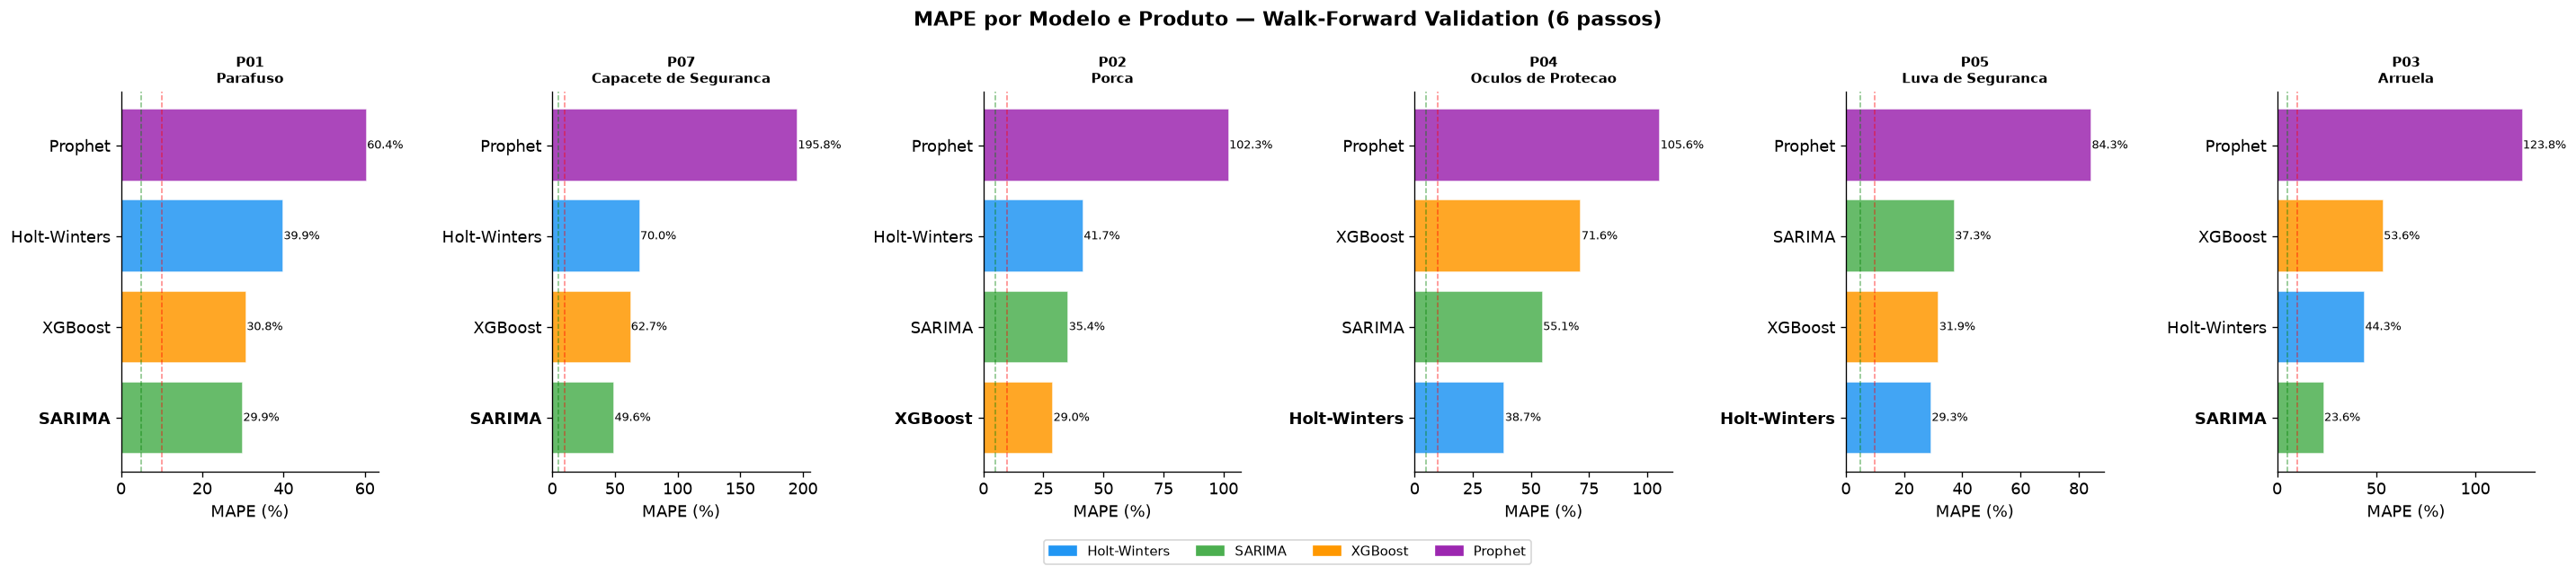

In [13]:
# Tabela resumo
print(f'\n{"="*65}')
print('  MELHOR MODELO POR PRODUTO')
print(f'{"="*65}')
rows_sum = []
for pid, df_res in resultados_por_produto.items():
    best = df_res.iloc[0]
    rows_sum.append({
        'ID':              pid,
        'Produto':         NOMES[pid],
        'Melhor Modelo':   best['Modelo'],
        'MAPE (%)':        best['MAPE (%)'],
        'MAE':             int(best['MAE']),
        'RMSE':            int(best['RMSE']),
    })
df_best = pd.DataFrame(rows_sum)
print(df_best.to_string(index=False))

# Grafico comparativo de MAPE
CORES_MOD = {'Holt-Winters': '#2196F3', 'SARIMA': '#4CAF50',
             'XGBoost': '#FF9800', 'Prophet': '#9C27B0'}

n_prods = len(IDS_AY)
fig, axes = plt.subplots(1, n_prods, figsize=(4 * n_prods, 5))
fig.suptitle('MAPE por Modelo e Produto — Walk-Forward Validation (6 passos)',
             fontsize=13, fontweight='bold')

for ax, (pid, df_res) in zip(axes, resultados_por_produto.items()):
    cores_bar = [CORES_MOD.get(m, '#888') for m in df_res['Modelo']]
    bars = ax.barh(df_res['Modelo'], df_res['MAPE (%)'],
                   color=cores_bar, alpha=0.85, edgecolor='white')
    ax.set_title(f"{pid}\n{NOMES[pid][:22]}", fontsize=9, fontweight='bold')
    ax.set_xlabel('MAPE (%)')
    ax.axvline(10, color='red',   lw=0.9, ls='--', alpha=0.5)
    ax.axvline(5,  color='green', lw=0.9, ls='--', alpha=0.5)
    for bar, val in zip(bars, df_res['MAPE (%)']):
        ax.text(val + 0.15, bar.get_y() + bar.get_height() / 2,
                f'{val:.1f}%', va='center', fontsize=8)
    # Destaca o melhor
    ax.get_yticklabels()[0].set_fontweight('bold')

handles = [Patch(color=c, label=n) for n, c in CORES_MOD.items()
           if n in MODELOS]
fig.legend(handles=handles, loc='lower center', ncol=4, fontsize=9,
           bbox_to_anchor=(0.5, -0.06))
plt.tight_layout()
plt.savefig('data/01_mape_comparativo.png', bbox_inches='tight')
plt.show()


## MAPE por Modelo e Produto — Walk-Forward Validation (6 passos)

> **MAPE** (Mean Absolute Percentage Error) — quanto menor, mais preciso o modelo.
> A linha vermelha tracejada indica o threshold de referência (~10%).

---

### P01 — Parafuso

| Modelo       | MAPE   | Ranking |
|--------------|:------:|:-------:|
| SARIMA       | 29,9%  | 1º      |
| XGBoost      | 30,8%  | 2º      |
| Holt-Winters | 39,9%  | 3º      |
| Prophet      | 60,4%  | 4º      |

> **SARIMA e XGBoost praticamente empatados** (29,9% vs 30,8%).
> É a única série não estacionária do grupo — a diferenciação do SARIMA ajuda aqui.

---

### P07 — Capacete de Segurança

| Modelo       | MAPE   | Ranking |
|--------------|:------:|:-------:|
| SARIMA       | 49,6%  | 1º      |
| XGBoost      | 62,7%  | 2º      |
| Holt-Winters | 70,0%  | 3º      |
| Prophet      | 195,9% | 4º      |

> **SARIMA é o melhor, mas com MAPE de 49,6%** — o produto mais difícil de prever.
> A janela de teste inclui jul/2024 (744 un., bem abaixo da média de 2.429), e um mês tão
> baixo infla o erro percentual: em unidades, o MAE do SARIMA é de 613 (~25% da média mensal).

---

### P02 — Porca

| Modelo       | MAPE   | Ranking |
|--------------|:------:|:-------:|
| XGBoost      | 29,0%  | 1º      |
| SARIMA       | 35,4%  | 2º      |
| Holt-Winters | 41,7%  | 3º      |
| Prophet      | 102,3% | 4º      |

> **XGBoost lidera** (29,0%) — único produto em que o modelo de machine learning vence.
> É a série de maior CV do grupo (0,46), o que favorece um modelo baseado em lags
> e médias móveis em vez de um padrão sazonal fixo.

---

### P04 — Óculos de Proteção

| Modelo       | MAPE   | Ranking |
|--------------|:------:|:-------:|
| Holt-Winters | 38,7%  | 1º      |
| SARIMA       | 55,1%  | 2º      |
| XGBoost      | 71,6%  | 3º      |
| Prophet      | 105,6% | 4º      |

> **Holt-Winters é o melhor**, mas com MAPE de 38,7% — acima da faixa aceitável.
> A janela de teste termina em dez/2024 (945 un., o menor valor dos últimos 12 meses),
> o que penaliza todos os modelos.

---

### P05 — Luva de Segurança

| Modelo       | MAPE   | Ranking |
|--------------|:------:|:-------:|
| Holt-Winters | 29,3%  | 1º      |
| XGBoost      | 31,9%  | 2º      |
| SARIMA       | 37,3%  | 3º      |
| Prophet      | 84,3%  | 4º      |

> **Holt-Winters lidera** com MAPE de 29,3%, com XGBoost logo atrás (31,9%).

---

### P03 — Arruela

| Modelo       | MAPE   | Ranking |
|--------------|:------:|:-------:|
| SARIMA       | 23,6%  | 1º      |
| Holt-Winters | 44,3%  | 2º      |
| XGBoost      | 53,6%  | 3º      |
| Prophet      | 123,8% | 4º      |

> **SARIMA vence com folga** (23,6%) — o melhor resultado de toda a validação,
> quase metade do erro do segundo colocado.

---

### Consolidado — Melhor Modelo por Produto

| Produto               | Melhor Modelo | MAPE    |
|-----------------------|:-------------:|:-------:|
| Arruela               | SARIMA        | 23,6%   |
| Porca                 | XGBoost       | 29,0%   |
| Luva de Segurança     | Holt-Winters  | 29,3%   |
| Parafuso              | SARIMA        | 29,9%   |
| Óculos de Proteção    | Holt-Winters  | 38,7%   |
| Capacete de Segurança | SARIMA        | 49,6%   |

---

### Conclusão

- **SARIMA** é o modelo mais consistente — melhor em 3 dos 6 produtos e com o menor MAPE médio (38,5%).
- **Holt-Winters** vence em 2 produtos (Óculos e Luva) e **XGBoost** em 1 (Porca).
- **Prophet** é o pior modelo nos 6 produtos, com MAPE de 60% a 196% — não recomendado
  para este portfólio. Com cerca de 30 pontos mensais de treino, o modelo provavelmente
  sobreajusta a sazonalidade anual.
- **Nenhum modelo fica abaixo de 20%**: quatro produtos ficam na faixa de 24% a 30% (aceitável
  para itens de alta variabilidade) e dois ficam acima de 30% (Óculos de Proteção e
  Capacete de Segurança). Os itens AY têm demanda genuinamente difícil de prever, o que
  justifica estoques de segurança robustos independentemente do modelo escolhido.

## 7. Previsão de Demanda — Próximos 3 Meses

Estratégia **recursiva**: a previsão do mês `t+1` é usada como observação para prever `t+2`, e assim sucessivamente.


In [14]:
def forecast_recursivo(serie, model_fn, n_steps):
    serie_ext = serie.copy()
    forecasts, datas = [], []
    for _ in range(n_steps):
        pred = max(0.0, float(model_fn(serie_ext)))
        next_date = serie_ext.index[-1] + pd.DateOffset(months=1)
        forecasts.append(pred)
        datas.append(next_date)
        nova = pd.Series([pred], index=[next_date], dtype=float)
        serie_ext = pd.concat([serie_ext, nova])
    return pd.Series(forecasts, index=datas)


previsoes = {}
print(f"{'Produto':<30} {'Modelo':<16} {'Jan/2025':>10} {'Fev/2025':>10} "
      f"{'Mar/2025':>10} {'Total 3m':>10}")
print('-' * 90)

for pid, serie in series.items():
    best_name = resultados_por_produto[pid].iloc[0]['Modelo']
    fc = forecast_recursivo(serie, MODELOS[best_name], HORIZONTE)
    previsoes[pid] = {'modelo': best_name, 'forecast': fc}
    vals = fc.values
    dts  = [d.strftime('%b/%Y') for d in fc.index]
    print(f"{NOMES[pid]:<30} {best_name:<16} "
          f"{vals[0]:>10,.0f} {vals[1]:>10,.0f} {vals[2]:>10,.0f} {vals.sum():>10,.0f}")


Produto                        Modelo             Jan/2025   Fev/2025   Mar/2025   Total 3m
------------------------------------------------------------------------------------------
Parafuso                       SARIMA               31,132     39,261     36,352    106,744


c:\Users\rafae\OneDrive\Documentos\Portifólio\Cadeia de Suprimentos - base revisadas\Cadeia de Suprimentos - base revisadas\.venv-1\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\rafae\OneDrive\Documentos\Portifólio\Cadeia de Suprimentos - base revisadas\Cadeia de Suprimentos - base revisadas\.venv-1\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\rafae\OneDrive\Documentos\Portifólio\Cadeia de Suprimentos - base revisadas\Cadeia de Suprimentos - base revisadas\.venv-1\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\rafae\OneDrive\Documentos\Portifólio\Cadeia de Supri

Capacete de Seguranca          SARIMA                3,937      2,516      3,081      9,534
Porca                          XGBoost              31,803     30,364     32,039     94,206


c:\Users\rafae\OneDrive\Documentos\Portifólio\Cadeia de Suprimentos - base revisadas\Cadeia de Suprimentos - base revisadas\.venv-1\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\rafae\OneDrive\Documentos\Portifólio\Cadeia de Suprimentos - base revisadas\Cadeia de Suprimentos - base revisadas\.venv-1\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\rafae\OneDrive\Documentos\Portifólio\Cadeia de Suprimentos - base revisadas\Cadeia de Suprimentos - base revisadas\.venv-1\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\rafae\OneDrive\Documentos\Portifólio\Cadeia de Supri

Oculos de Protecao             Holt-Winters          3,231      2,031      3,503      8,764
Luva de Seguranca              Holt-Winters          2,114      2,512      3,422      8,048
Arruela                        SARIMA               23,546     50,050     15,885     89,482


c:\Users\rafae\OneDrive\Documentos\Portifólio\Cadeia de Suprimentos - base revisadas\Cadeia de Suprimentos - base revisadas\.venv-1\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\rafae\OneDrive\Documentos\Portifólio\Cadeia de Suprimentos - base revisadas\Cadeia de Suprimentos - base revisadas\.venv-1\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\rafae\OneDrive\Documentos\Portifólio\Cadeia de Suprimentos - base revisadas\Cadeia de Suprimentos - base revisadas\.venv-1\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\rafae\OneDrive\Documentos\Portifólio\Cadeia de Supri

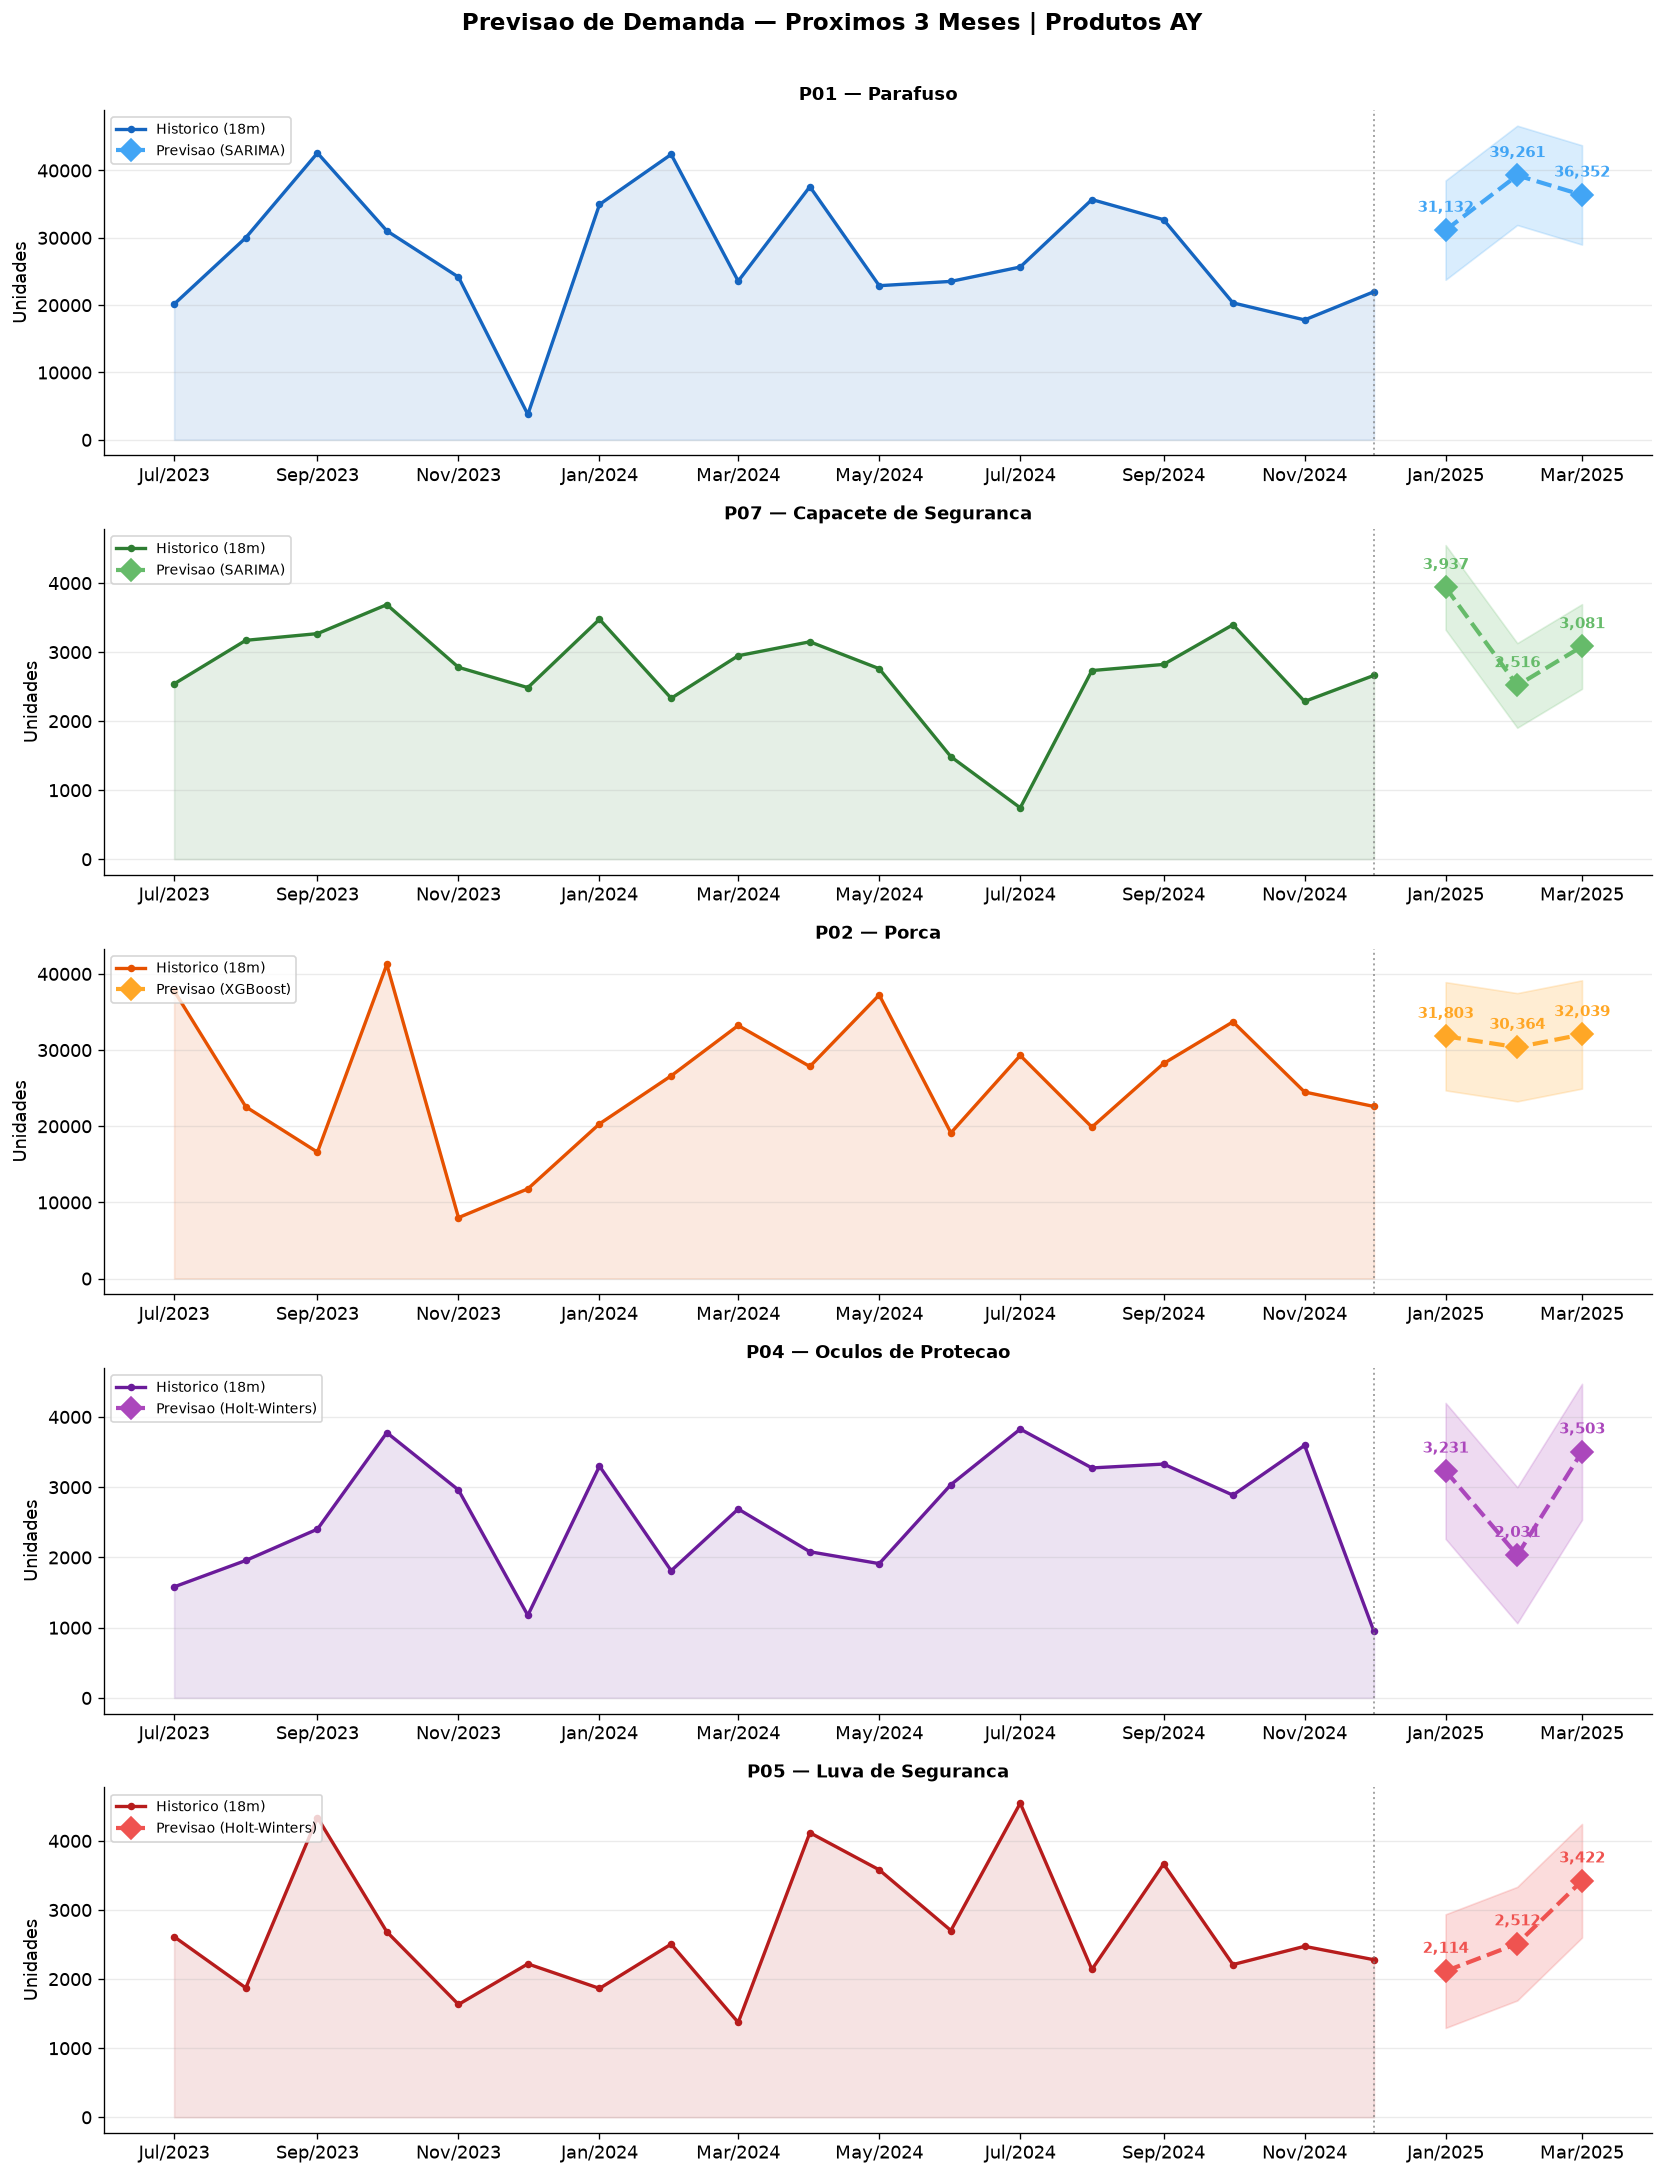

In [15]:
CORES_HIST = ['#1565C0', '#2E7D32', '#E65100', '#6A1B9A', '#B71C1C', '#00838F']
CORES_FC   = ['#42A5F5', '#66BB6A', '#FFA726', '#AB47BC', '#EF5350', '#26C6DA']

# Um painel por produto AY (a quantidade vem da classificação ABC-XYZ)
n_fc = len(previsoes)
fig, axes = plt.subplots(n_fc, 1, figsize=(14, 3.6 * n_fc))
fig.suptitle(f'Previsao de Demanda — Proximos {HORIZONTE} Meses | Produtos AY',
             fontsize=14, fontweight='bold', y=1.005)

for ax, (pid, info), ch, cf in zip(axes, previsoes.items(), CORES_HIST, CORES_FC):
    s   = series[pid]
    fc  = info['forecast']
    mod = info['modelo']
    mae_best = float(resultados_por_produto[pid].iloc[0]['MAE'])

    # Historico — ultimos 18 meses
    hist = s.iloc[-18:]
    ax.fill_between(hist.index, hist.values, alpha=0.12, color=ch)
    ax.plot(hist.index, hist.values, color=ch, lw=2, marker='o', ms=3.5,
            label='Historico (18m)')

    # Banda de incerteza (+/- 1 MAE)
    ax.fill_between(fc.index,
                    (fc.values - mae_best).clip(0),
                    fc.values + mae_best,
                    alpha=0.20, color=cf)
    ax.plot(fc.index, fc.values, color=cf, lw=2.5, marker='D', ms=9,
            ls='--', label=f'Previsao ({mod})')

    # Linha divisoria
    ax.axvline(s.index[-1], color='gray', lw=1.2, ls=':', alpha=0.7)

    # Anotacoes nos pontos previstos
    for d, v in zip(fc.index, fc.values):
        ax.annotate(
            f'{v:,.0f}',
            xy=(d, v), xytext=(0, 11),
            textcoords='offset points',
            ha='center', fontsize=9, fontweight='bold', color=cf,
        )

    ax.set_title(f'{pid} — {NOMES[pid]}', fontweight='bold', fontsize=11)
    ax.set_ylabel('Unidades')
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%b/%Y'))
    ax.grid(axis='y', alpha=0.25)
    ax.legend(fontsize=8.5, loc='upper left')

plt.tight_layout()
plt.savefig('data/02_previsao_AY_3meses.png', bbox_inches='tight')
plt.show()

## 8. Resultado Final


In [16]:
# Monta tabela final
resultado_final = pd.DataFrame(index=IDS_AY)
resultado_final.index.name = 'id_produto'
resultado_final['produto']       = [NOMES[p] for p in IDS_AY]
resultado_final['modelo_usado']  = [previsoes[p]['modelo'] for p in IDS_AY]
resultado_final['mape_pct']      = [resultados_por_produto[p].iloc[0]['MAPE (%)'] for p in IDS_AY]
resultado_final['mae']           = [int(resultados_por_produto[p].iloc[0]['MAE']) for p in IDS_AY]

for i in range(HORIZONTE):
    col = previsoes[IDS_AY[0]]['forecast'].index[i].strftime('prev_%Y_%m')
    resultado_final[col] = [int(previsoes[p]['forecast'].iloc[i]) for p in IDS_AY]

resultado_final['prev_total_3m'] = resultado_final[
    [c for c in resultado_final.columns if c.startswith('prev_')]
].sum(axis=1)

print('=' * 100)
print('PREVISAO DE DEMANDA — PRODUTOS AY | Proximos 3 Meses')
print('=' * 100)
print(resultado_final.to_string())

resultado_final.to_csv('data/previsao_demanda_AY.csv', encoding='utf-8-sig')
print('\nSalvo: data/previsao_demanda_AY.csv')


PREVISAO DE DEMANDA — PRODUTOS AY | Proximos 3 Meses
                          produto  modelo_usado  mape_pct   mae  prev_2025_01  prev_2025_02  prev_2025_03  prev_total_3m
id_produto                                                                                                              
P01                      Parafuso        SARIMA     29.91  7372         31132         39260         36351         106743
P07         Capacete de Seguranca        SARIMA     49.63   613          3936          2516          3080           9532
P02                         Porca       XGBoost     29.01  7106         31802         30363         32039          94204
P04            Oculos de Protecao  Holt-Winters     38.72   968          3230          2030          3502           8762
P05             Luva de Seguranca  Holt-Winters     29.32   822          2114          2511          3421           8046
P03                       Arruela        SARIMA     23.61  5668         23545         50050         

---
## Notas Metodológicas

### Por que Walk-Forward e não K-Fold?
K-Fold embaralha os dados, permitindo que observações futuras "vazem" para o treino. Em séries temporais isso infla artificialmente a acurácia. O walk-forward respeita a ordem cronológica: sempre treinamos no passado e testamos no futuro.

### Modelos avaliados

| Modelo | Tipo | Vantagem | Limitação |
|---|---|---|---|
| **Holt-Winters** | Estatístico | Captura tendência + sazonalidade | Assume padrão fixo |
| **SARIMA** | Estatístico | Flexível para autocorrelação | Sensível a parâmetros |
| **XGBoost** | ML | Captura não-linearidades via lag features | Precisa de dados suficientes |
| **Prophet** | Bayesiano | Robusto a changepoints | Com 36 meses pode ser conservador |

### Interpretação do MAPE
- **< 10 %** — excelente
- **10–20 %** — bom para demanda variável (CV > 0,20)
- **20–30 %** — aceitável para itens de alta variabilidade (classe Y)
- **> 30 %** — revisar modelo ou coletar mais dados

> Os produtos AY têm CV entre 0,36 e 0,46. Os melhores modelos ficaram com MAPE entre 24 % e 50 %:
> quatro produtos na faixa aceitável (20–30 %) e dois acima de 30 % (Óculos de Proteção, 38,7 %,
> e Capacete de Segurança, 49,6 %), que pedem revisão de modelo ou mais histórico.
